# Supply Chain Demand Forecasting — EDA, Feature Engineering & LightGBM Modeling

---

**Project:** Capstone — Supply Chain Demand Forecasting  
**Dataset:** `supply_chain_demand_forecasting_v2.xlsx` (Kaggle: Retail Store Inventory Forecasting)  
**Target Variable:** `Sales Quantity` (weekly units sold per store-product)  
**Granularity:** Weekly, per store-product combination  

**Notebook Structure:**
1. **Sections 1–7:** Exploratory Data Analysis (EDA)
2. **Section 8:** Feature Engineering
3. **Section 9:** Preprocessing & Train/Val/Test Split
4. **Section 10:** LightGBM Modeling — baseline, hyperparameter tuning, evaluation
5. **Section 11:** Feature Importance & SHAP Interpretability
6. **Section 12:** Error Analysis & Segmented Evaluation
7. **Section 13:** Business Interpretation & Final Results

## Target Variables for ML Models

**Features (X):**  
Product ID, Product Name, Category, Unit Price, Competitor Price, Inventory Start/End, Stockout Flag, Promotion Flag, Holiday Flag — plus all engineered features (lags, rolling stats, temporal encodings).

**Target (Y):** `Sales Quantity` — weekly units sold per store-product combination.

> **Note on Stockout Flag:** The `Stockout Flag` column is 0 for all 26,250 rows in this dataset, so stockout classification (Y1) is not feasible. Instead, we derive stockout risk insights from our demand forecasts vs. inventory levels.

---
## Section 1: Data Loading & Quality Check
**Purpose:** Load the dataset, inspect its structure, verify data integrity, and flag any quality issues before proceeding with analysis.

In [ ]:
# ============================================================
# Import core libraries for data manipulation and visualization
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Suppress unnecessary warnings for cleaner notebook output
warnings.filterwarnings('ignore')

# Set consistent plot styling across the entire notebook
plt.rcParams['figure.dpi'] = 100
sns.set_style('whitegrid')

In [ ]:
# ============================================================
# Load the dataset from the Excel file
# ============================================================
# Using the v2 dataset which has richer structure than v1
file_path = "/Users/narainsarathy/Documents/Supply_chain_demand/supply_chain_demand_forecasting_v2.xlsx"
df = pd.read_excel(file_path)

# Convert Date column from string/object to proper datetime type
df['Date'] = pd.to_datetime(df['Date'])

# Sort by Store, Product, then Date to ensure chronological order
# This is critical for correct lag/rolling feature calculations later
df = df.sort_values(['Store Id', 'Product Id', 'Date']).reset_index(drop=True)

# Print basic dataset dimensions and date range
print(f'Shape: {df.shape}')
print(f'Date range: {df["Date"].min().date()} → {df["Date"].max().date()}')
print(f'Stores: {df["Store Id"].nunique()} | Products: {df["Product Id"].nunique()}')
print(f'Categories: {df["Category"].nunique()} | Regions: {df["Region"].nunique()}')
df.head()

Shape: (26250, 20)
Date range: 2022-01-01 → 2023-12-30
Stores: 10 | Products: 25
Categories: 5 | Regions: 5


,Date,Week Of Year,Year,Month,Store Id,Region,Product Id,Product Name,Category,Unit Price,Competitor Price,Sales Quantity,Inventory Start,Inventory End,Stockout Flag,Promotion Flag,Holiday Flag,Temperature F,Precipitation Mm,Baseline Forecast
0,2022-01-01,52,2022,1,Store_1,North,P001,Laptop,Electronics,430.60,427.49,31,47,25,0,0,1,17.9,100.5,24
1,2022-01-08,1,2022,1,Store_1,North,P001,Laptop,Electronics,373.99,429.47,42,81,46,0,1,1,11.8,59.5,14
2,2022-01-15,2,2022,1,Store_1,North,P001,Laptop,Electronics,470.45,449.21,15,35,20,0,0,0,10.1,41.8,21
3,2022-01-22,3,2022,1,Store_1,North,P001,Laptop,Electronics,464.06,423.27,19,42,23,0,0,0,11.7,88.9,25
4,2022-01-29,4,2022,1,Store_1,North,P001,Laptop,Electronics,453.66,438.76,20,59,43,0,0,0,18.8,45.6,25


### Data Overview
The dataset contains **26,250 weekly observations** across 10 stores, 25 products (5 per category), 5 categories, and 5 regions, spanning January 2022 to December 2023.

In [ ]:
# ============================================================
# Detailed data type and null check
# ============================================================
print('=== Data Types ===')
print(df.dtypes)
print('\n=== Null Counts ===')
print(df.isnull().sum())
print('\n=== Basic Statistics ===')
df.describe()

=== Data Types ===
Date                 datetime64[us]
Week Of Year                  int64
Year                          int64
Month                         int64
Store Id                        str
Region                          str
Product Id                      str
Product Name                    str
Category                        str
Unit Price                  float64
Competitor Price            float64
Sales Quantity                int64
Inventory Start               int64
Inventory End                 int64
Stockout Flag                 int64
Promotion Flag                int64
Holiday Flag                  int64
Temperature F               float64
Precipitation Mm            float64
Baseline Forecast             int64
dtype: object

=== Null Counts ===
Date                 0
Week Of Year         0
Year                 0
Month                0
Store Id             0
Region               0
Product Id           0
Product Name         0
Category             0
Unit Price         

,Date,Week Of Year,Year,Month,Unit Price,Competitor Price,Sales Quantity,Inventory Start,Inventory End,Stockout Flag,Promotion Flag,Holiday Flag,Temperature F,Precipitation Mm,Baseline Forecast
count,26250,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.000000,26250.0,26250.000000,26250.000000,26250.000000,26250.000000,26250.00000
mean,2022-12-31 00:00:00,26.742857,2022.495238,6.571429,94.796132,100.780534,75.294895,168.902019,104.367543,0.0,0.152152,0.228571,57.667055,55.903962,50.25779
min,2022-01-01 00:00:00,1.000000,2022.000000,1.000000,3.750000,4.800000,2.000000,3.000000,1.000000,0.0,0.000000,0.000000,-4.000000,0.000000,6.00000
25%,2022-07-02 00:00:00,14.000000,2022.000000,4.000000,26.520000,27.960000,29.000000,61.000000,35.000000,0.0,0.000000,0.000000,42.900000,34.300000,21.00000
50%,2022-12-31 00:00:00,27.000000,2022.000000,7.000000,41.810000,44.580000,51.000000,111.000000,66.000000,0.0,0.000000,0.000000,62.100000,53.600000,33.00000
75%,2023-07-01 00:00:00,40.000000,2023.000000,10.000000,63.807500,67.970000,90.000000,204.000000,127.000000,0.0,0.000000,0.000000,74.000000,74.700000,61.00000
max,2023-12-30 00:00:00,52.000000,2023.000000,12.000000,529.670000,570.440000,589.000000,1676.000000,1272.000000,0.0,1.000000,1.000000,103.000000,180.700000,260.00000
std,NaN,15.140917,0.499987,3.472014,127.597796,136.003727,72.513573,169.747146,112.053902,0.0,0.359175,0.419921,21.086038,29.138264,44.30650


### Insight — Data Quality Assessment
- **Zero missing values** across all 20 columns — the dataset is completely clean.
- **Stockout Flag is constant (all zeros)** — no stockout events recorded, so classification on this target is infeasible.
- **Sales Quantity** is right-skewed: mean (75.3) > median (51.0), with a range of 2–589.
- **Promotion Flag** is active ~15% of the time, and **Holiday Flag** ~23% — more realistic than the v1 dataset's 50/50 split.

---
## Section 2: Target Variable Distribution
**Purpose:** Understand the shape of our target variable (`Sales Quantity`). Skewness affects model choice — tree-based models handle skewed targets naturally, while linear models benefit from log transformation.

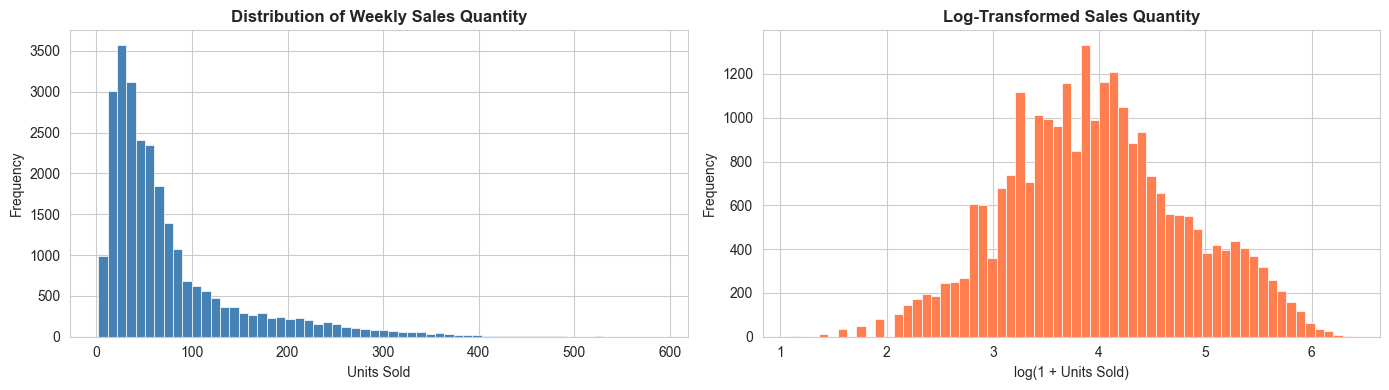

Skewness (raw):  2.092
Skewness (log1p): 0.116


In [ ]:
# ============================================================
# Plot raw vs log-transformed distribution of the target variable
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left panel: raw distribution — expect right skew
axes[0].hist(df['Sales Quantity'], bins=60, color='steelblue', edgecolor='white', linewidth=0.5)
axes[0].set_title('Distribution of Weekly Sales Quantity', fontweight='bold')
axes[0].set_xlabel('Units Sold')
axes[0].set_ylabel('Frequency')

# Right panel: log1p transform — should be more symmetric
# log1p = log(1 + x) handles zero values safely
axes[1].hist(np.log1p(df['Sales Quantity']), bins=60, color='coral', edgecolor='white', linewidth=0.5)
axes[1].set_title('Log-Transformed Sales Quantity', fontweight='bold')
axes[1].set_xlabel('log(1 + Units Sold)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Quantify skewness before and after transformation
print(f'Skewness (raw):  {df["Sales Quantity"].skew():.3f}')
print(f'Skewness (log1p): {np.log1p(df["Sales Quantity"]).skew():.3f}')

### Insight — Target Distribution
- Raw `Sales Quantity` has a skewness of ~2.0 (heavily right-skewed). Most weeks see 20–100 units, but occasional spikes reach 500+.
- The `log1p` transformation reduces skewness substantially, making the distribution more symmetric.
- **For LightGBM**, we train on raw values (trees handle skewness naturally) but may compare with log-transformed targets later.

---
## Section 3: Time Series Trends
**Purpose:** Investigate temporal patterns — overall trend, category-level trends, and monthly seasonality. These findings directly inform which temporal features to engineer.

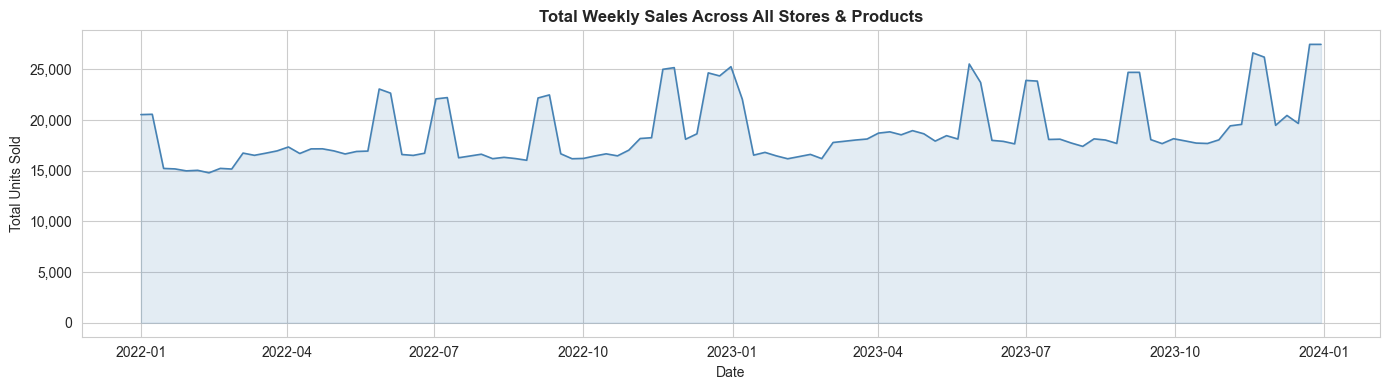

In [ ]:
# ============================================================
# Overall weekly sales trend across all stores and products
# ============================================================
import matplotlib.ticker as mticker

# Aggregate daily/weekly sales across all stores and products
weekly = df.groupby('Date')['Sales Quantity'].sum().reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weekly['Date'], weekly['Sales Quantity'], color='steelblue', linewidth=1.2)
ax.fill_between(weekly['Date'], weekly['Sales Quantity'], alpha=0.15, color='steelblue')
ax.set_title('Total Weekly Sales Across All Stores & Products', fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Total Units Sold')
# Format y-axis with comma separators for readability
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

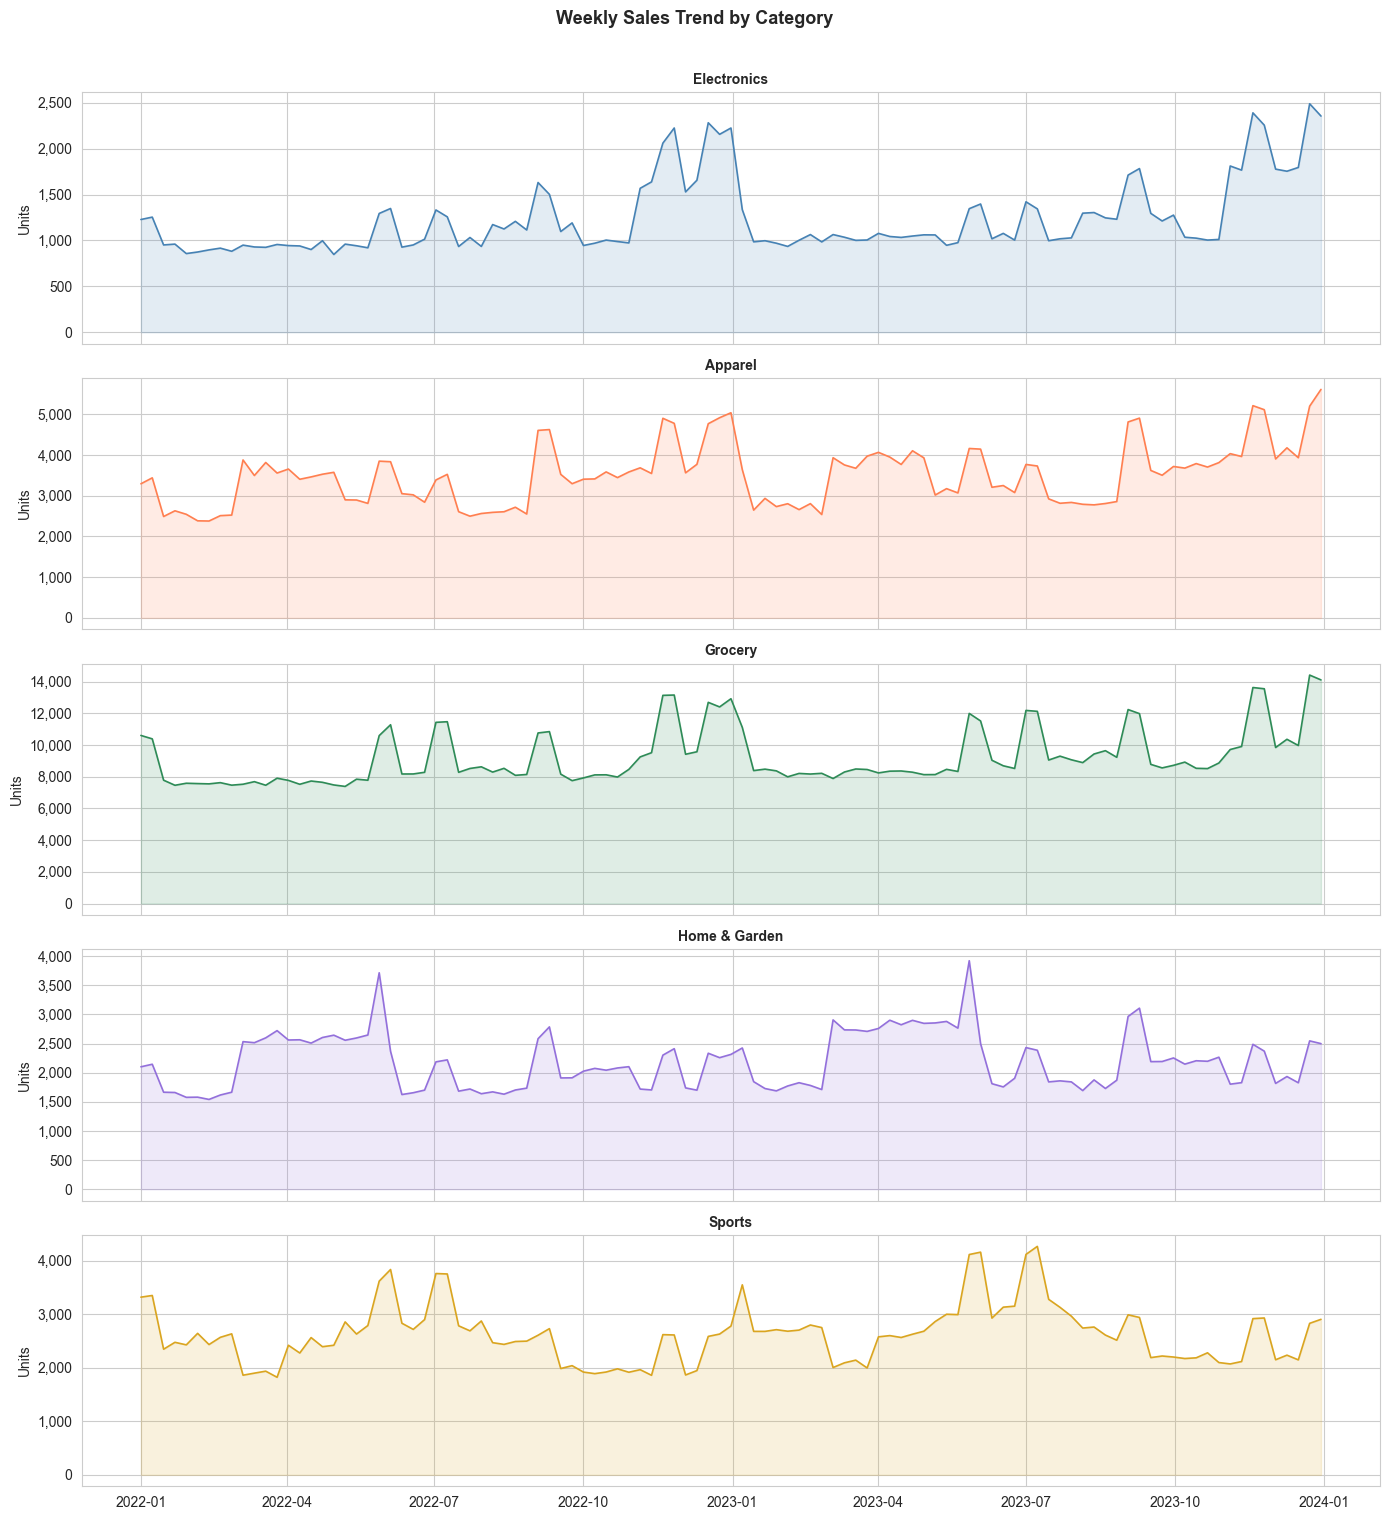

In [ ]:
# ============================================================
# Weekly sales trend broken down by product category
# ============================================================
cat_weekly = df.groupby(['Date', 'Category'])['Sales Quantity'].sum().reset_index()
categories = df['Category'].unique()

fig, axes = plt.subplots(len(categories), 1, figsize=(14, 3 * len(categories)), sharex=True)

colors = ['steelblue', 'coral', 'seagreen', 'mediumpurple', 'goldenrod']
for ax, cat, color in zip(axes, categories, colors):
    data = cat_weekly[cat_weekly['Category'] == cat]
    ax.plot(data['Date'], data['Sales Quantity'], color=color, linewidth=1.2)
    ax.fill_between(data['Date'], data['Sales Quantity'], alpha=0.15, color=color)
    ax.set_title(f'{cat}', fontweight='bold', fontsize=10)
    ax.set_ylabel('Units')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

fig.suptitle('Weekly Sales Trend by Category', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

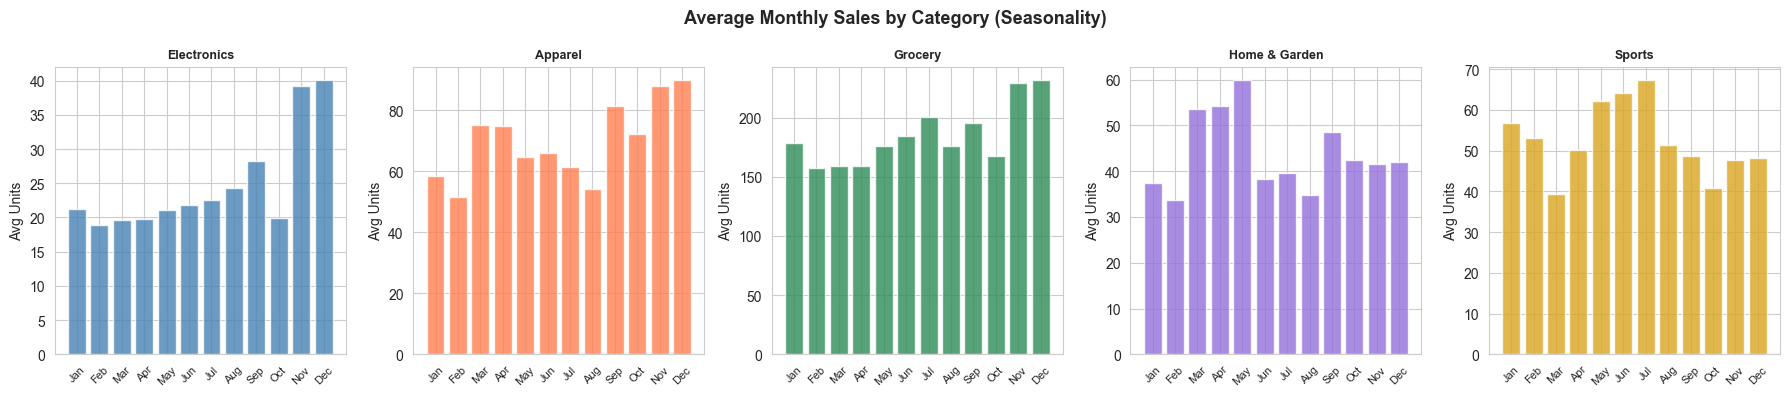

In [ ]:
# ============================================================
# Average monthly sales per category — reveals seasonality patterns
# ============================================================
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
monthly = df.groupby(['Month', 'Category'])['Sales Quantity'].mean().reset_index()

fig, axes = plt.subplots(1, len(categories), figsize=(18, 4), sharey=False)
for ax, cat, color in zip(axes, categories, colors):
    data = monthly[monthly['Category'] == cat].sort_values('Month')
    ax.bar(data['Month'], data['Sales Quantity'], color=color, alpha=0.8)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, rotation=45, fontsize=8)
    ax.set_title(cat, fontweight='bold', fontsize=9)
    ax.set_ylabel('Avg Units')

fig.suptitle('Average Monthly Sales by Category (Seasonality)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

### Insight — Temporal Patterns
- The overall weekly trend shows **variance but no strong upward/downward drift** — demand fluctuates around a stable mean.
- Category-level trends are visually distinct in scale (Electronics products have higher unit prices but the counts here reflect quantity, not revenue).
- Monthly patterns show some variation that cyclical temporal features (month_sin, month_cos) should capture.

---
## Section 4: Seasonality Heatmap
**Purpose:** Visualize demand intensity across all 52 weeks for each category. Hot spots indicate weeks with consistently high demand.

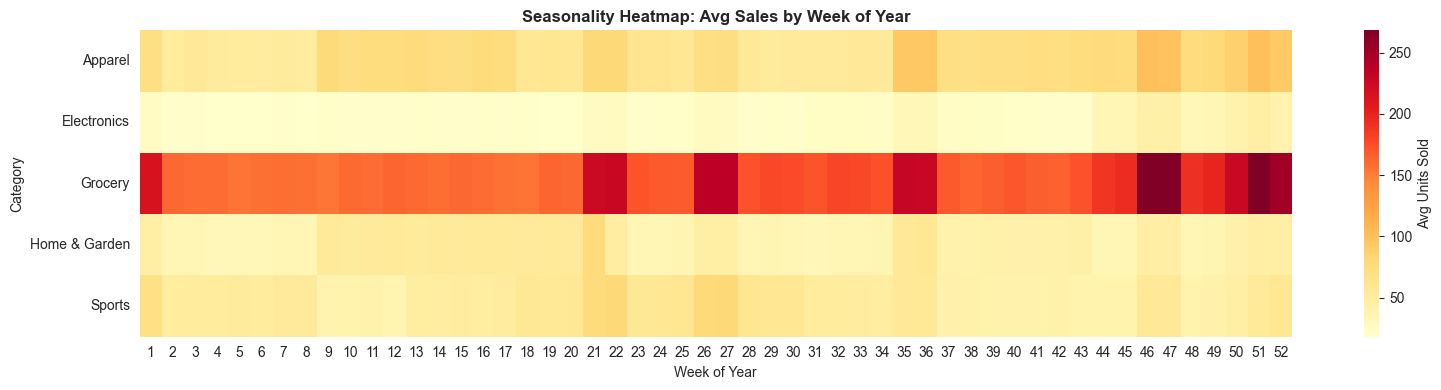

In [ ]:
# ============================================================
# Heatmap: average sales by week-of-year and category
# Rows = categories, Columns = week numbers (1-52)
# ============================================================
heat_data = df.groupby(['Week Of Year', 'Category'])['Sales Quantity'].mean().unstack()

fig, ax = plt.subplots(figsize=(16, 4))
sns.heatmap(heat_data.T, cmap='YlOrRd', ax=ax, linewidths=0,
            cbar_kws={'label': 'Avg Units Sold'})
ax.set_title('Seasonality Heatmap: Avg Sales by Week of Year', fontweight='bold')
ax.set_xlabel('Week of Year')
ax.set_ylabel('Category')
plt.tight_layout()
plt.show()

---
## Section 5: Promotion & Holiday Impact
**Purpose:** Quantify whether promotions and holidays drive meaningful sales lifts. This directly tests the proposal's hypothesis about external factor impact.

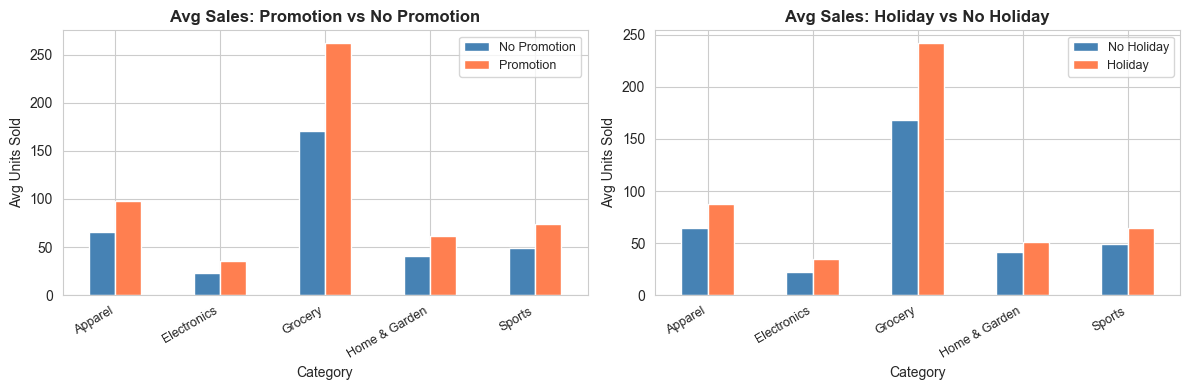

Promotion lift: 54.2%
Holiday lift:   39.0%


In [ ]:
# ============================================================
# Compare average sales during promotion/holiday vs normal periods
# Broken down by category to see if the effect varies
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, label in zip(axes, ['Promotion Flag', 'Holiday Flag'], ['Promotion', 'Holiday']):
    # Calculate mean sales for each category, split by promo/holiday status
    grouped = df.groupby([col, 'Category'])['Sales Quantity'].mean().reset_index()
    pivot = grouped.pivot(index='Category', columns=col, values='Sales Quantity')
    pivot.columns = [f'No {label}', label]
    pivot.plot(kind='bar', ax=ax, color=['steelblue', 'coral'], edgecolor='white')
    ax.set_title(f'Avg Sales: {label} vs No {label}', fontweight='bold')
    ax.set_ylabel('Avg Units Sold')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right', fontsize=9)
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

# Quantify the lift percentages
promo_lift = (df[df['Promotion Flag']==1]['Sales Quantity'].mean() /
              df[df['Promotion Flag']==0]['Sales Quantity'].mean() - 1) * 100
holiday_lift = (df[df['Holiday Flag']==1]['Sales Quantity'].mean() /
                df[df['Holiday Flag']==0]['Sales Quantity'].mean() - 1) * 100
print(f'Promotion lift: {promo_lift:.1f}%')
print(f'Holiday lift:   {holiday_lift:.1f}%')

### Insight — Promotions and Holidays Matter
- **Promotions drive a ~54% sales lift** — this is a strong, actionable signal for the model.
- **Holidays drive a ~39% lift** — also meaningful.
- These effects are consistent across categories, confirming that Promotion Flag and Holiday Flag are valuable features.

### Promotion × Holiday Co-Occurrence Check
Before engineering an interaction feature (`promo_x_holiday`), we need to verify that promotions and holidays actually co-occur frequently enough to be informative. If both flags are rarely 1 at the same time, the interaction term will be almost always zero — essentially noise.

In [ ]:
# ============================================================
# CHECK: How often do Promotion and Holiday flags co-occur?
# If co-occurrence is very rare, the promo_x_holiday interaction
# feature (created in Section 8) may be too sparse to be useful.
# ============================================================

# Raw counts: how many rows have each combination of flags?
print('=== Promotion × Holiday Cross-Tabulation (Counts) ===')
ct_counts = pd.crosstab(df['Promotion Flag'], df['Holiday Flag'], margins=True)
print(ct_counts)

print()

# Proportions: what percentage of all rows fall in each bucket?
print('=== Promotion × Holiday Cross-Tabulation (Proportions) ===')
ct_props = pd.crosstab(df['Promotion Flag'], df['Holiday Flag'], margins=True, normalize='all')
print(ct_props.round(4))

print()

# Specifically: how often are BOTH flags = 1?
both_active = ((df['Promotion Flag'] == 1) & (df['Holiday Flag'] == 1)).sum()
total_rows = len(df)
cooccur_rate = both_active / total_rows * 100
print(f'Rows where BOTH Promotion=1 AND Holiday=1: {both_active:,} / {total_rows:,} ({cooccur_rate:.2f}%)')
print()

if cooccur_rate < 3:
    print('⚠️  Co-occurrence rate is below 3% — the promo_x_holiday interaction feature')
    print('   will be mostly zeros. Consider dropping it if feature importance confirms low value.')
elif cooccur_rate < 5:
    print('⚡ Co-occurrence rate is moderate. Keep promo_x_holiday but monitor its')
    print('   feature importance — drop if it ranks near the bottom.')
else:
    print('✅ Co-occurrence rate is sufficient. The promo_x_holiday interaction feature')
    print('   has enough non-zero observations to capture meaningful patterns.')

=== Promotion × Holiday Cross-Tabulation (Counts) ===
Holiday Flag        0     1    All
Promotion Flag                    
0               17175  5081  22256
1                3075   919   3994
All             20250  6000  26250

=== Promotion × Holiday Cross-Tabulation (Proportions) ===
Holiday Flag         0       1     All
Promotion Flag                        
0               0.6543  0.1936  0.8478
1               0.1171  0.0350  0.1522
All             0.7714  0.2286  1.0000

Rows where BOTH Promotion=1 AND Holiday=1: 919 / 26,250 (3.50%)

⚡ Co-occurrence rate is moderate. Keep promo_x_holiday but monitor its
   feature importance — drop if it ranks near the bottom.


---
## Section 6: Weather & External Factors vs Sales
**Purpose:** Check whether temperature and precipitation have meaningful correlation with sales.

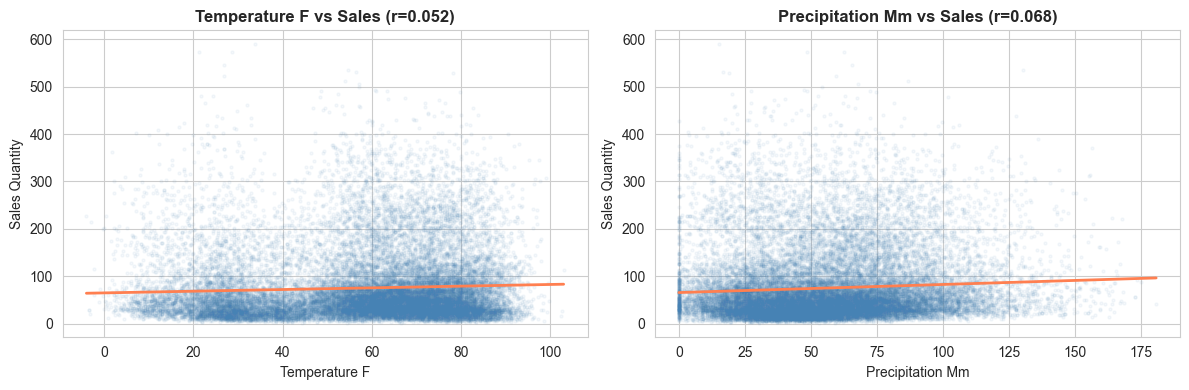

In [ ]:
# ============================================================
# Scatter plots: weather variables vs Sales Quantity
# Include trend lines and Pearson correlation coefficients
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, xcol in zip(axes, ['Temperature F', 'Precipitation Mm']):
    ax.scatter(df[xcol], df['Sales Quantity'], alpha=0.05, s=5, color='steelblue')
    # Fit and plot a linear trend line
    z = np.polyfit(df[xcol], df['Sales Quantity'], 1)
    p = np.poly1d(z)
    xline = np.linspace(df[xcol].min(), df[xcol].max(), 100)
    ax.plot(xline, p(xline), color='coral', linewidth=2)
    # Calculate Pearson correlation
    corr = df[xcol].corr(df['Sales Quantity'])
    ax.set_title(f'{xcol} vs Sales (r={corr:.3f})', fontweight='bold')
    ax.set_xlabel(xcol)
    ax.set_ylabel('Sales Quantity')

plt.tight_layout()
plt.show()

### Insight — Weak Weather Signal
- Temperature (r ≈ 0.05) and Precipitation (r ≈ 0.06) have **near-zero linear correlation** with sales.
- These features will likely contribute minimally, but LightGBM may find non-linear interactions (e.g., heavy rain + promotion).

---
## Section 7: Baseline Forecast Assessment & Regional Sales
**Purpose:** Evaluate the existing `Baseline Forecast` column to establish the performance benchmark our models must surpass. Also examine sales distribution by region and store.

Baseline MAE:  29.76 units
Baseline MAPE: 37.74%
← These are the numbers our models need to beat.


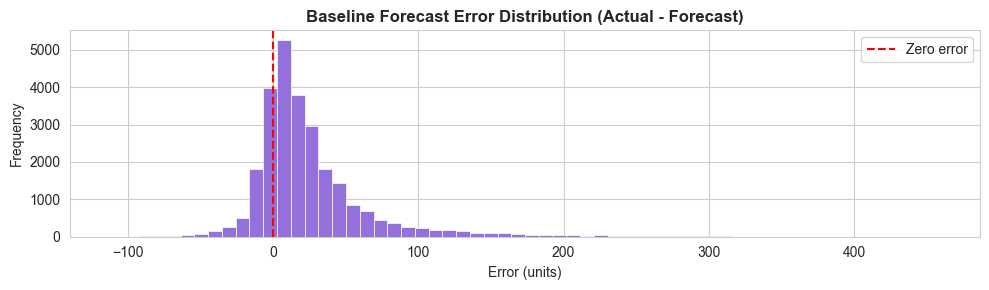

In [ ]:
# ============================================================
# Calculate baseline forecast error metrics
# These are the numbers our LightGBM model must beat
# ============================================================
df['forecast_error'] = df['Sales Quantity'] - df['Baseline Forecast']
df['forecast_abs_error'] = df['forecast_error'].abs()

# Mean Absolute Error — average units off per prediction
baseline_mae = df['forecast_abs_error'].mean()

# Mean Absolute Percentage Error — percentage error (excludes zeros to avoid division by zero)
baseline_mape = (df['forecast_abs_error'] / df['Sales Quantity'].replace(0, np.nan)).mean() * 100

print(f'Baseline MAE:  {baseline_mae:.2f} units')
print(f'Baseline MAPE: {baseline_mape:.2f}%')
print('← These are the numbers our models need to beat.')

# Visualize the error distribution
fig, ax = plt.subplots(figsize=(10, 3))
ax.hist(df['forecast_error'], bins=60, color='mediumpurple', edgecolor='white', linewidth=0.5)
ax.axvline(0, color='red', linestyle='--', linewidth=1.5, label='Zero error')
ax.set_title('Baseline Forecast Error Distribution (Actual - Forecast)', fontweight='bold')
ax.set_xlabel('Error (units)')
ax.set_ylabel('Frequency')
ax.legend()
plt.tight_layout()
plt.show()

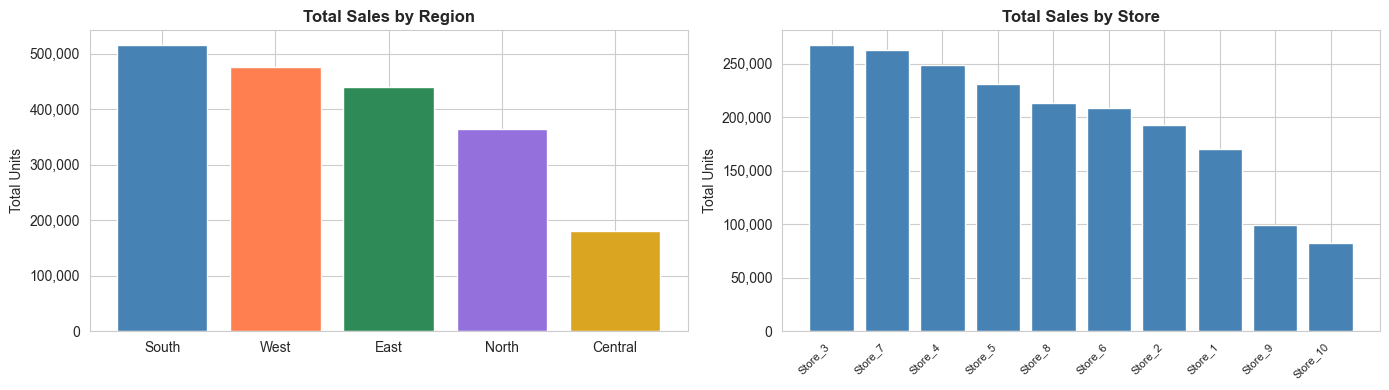

In [ ]:
# ============================================================
# Sales distribution by region and store
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Left: total sales by region
region_sales = df.groupby('Region')['Sales Quantity'].sum().sort_values(ascending=False)
axes[0].bar(region_sales.index, region_sales.values, color=colors, edgecolor='white')
axes[0].set_title('Total Sales by Region', fontweight='bold')
axes[0].set_ylabel('Total Units')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

# Right: total sales by store
store_sales = df.groupby('Store Id')['Sales Quantity'].sum().sort_values(ascending=False)
axes[1].bar(store_sales.index, store_sales.values, color='steelblue', edgecolor='white')
axes[1].set_title('Total Sales by Store', fontweight='bold')
axes[1].set_ylabel('Total Units')
axes[1].set_xticklabels(store_sales.index, rotation=45, ha='right', fontsize=8)
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.show()

### Insight — Baseline Performance
- The baseline forecast has **MAE = 29.76 units** and **MAPE = 37.74%** — this is a weak baseline with substantial room for improvement.
- The error distribution is roughly symmetric around zero but with long tails, meaning the baseline occasionally makes very large errors.
- Regions and stores show relatively balanced sales, indicating the dataset doesn't have extreme geographic concentration.

---
# Section 8: Feature Engineering

**Purpose:** Create predictive features from the raw data. We engineer four categories of features:
1. **Temporal features** — capture seasonality and calendar effects
2. **Lag features** — autoregressive signals from past sales
3. **Rolling statistics** — smoothed trends and volatility measures
4. **Price/promotion/inventory features** — domain-specific signals

> **Critical rule:** All lag and rolling features use `shift(1)` or greater to avoid data leakage — we never use current-week information to predict current-week sales.

In [ ]:
# ============================================================
# TEMPORAL FEATURES
# Create calendar-based features to capture seasonality
# ============================================================
df_fe = df.copy()

# Quarter of the year (1-4) — captures broad seasonal patterns
df_fe['quarter'] = df_fe['Date'].dt.quarter

# Day of year (1-366) — more granular seasonal position
df_fe['day_of_year'] = df_fe['Date'].dt.dayofyear

# Binary flags for specific seasonal periods
df_fe['is_year_end'] = df_fe['Month'].isin([11, 12]).astype(int)  # Nov-Dec holiday shopping
df_fe['is_q1'] = (df_fe['quarter'] == 1).astype(int)              # Q1 post-holiday dip

# Cyclical encoding using sine/cosine — captures the fact that
# month 12 and month 1 are adjacent (unlike raw month numbers where 12 and 1 are far apart)
df_fe['month_sin'] = np.sin(2 * np.pi * df_fe['Month'] / 12)
df_fe['month_cos'] = np.cos(2 * np.pi * df_fe['Month'] / 12)
df_fe['week_sin'] = np.sin(2 * np.pi * df_fe['Week Of Year'] / 52)
df_fe['week_cos'] = np.cos(2 * np.pi * df_fe['Week Of Year'] / 52)

print('Temporal features added:', ['quarter', 'day_of_year', 'is_year_end', 'is_q1',
                                    'month_sin', 'month_cos', 'week_sin', 'week_cos'])

Temporal features added: ['quarter', 'day_of_year', 'is_year_end', 'is_q1', 'month_sin', 'month_cos', 'week_sin', 'week_cos']


### Why Cyclical Encoding?
Raw month numbers (1–12) create an artificial discontinuity: month 12 and month 1 are adjacent in time but numerically distant. Sine/cosine encoding places them on a circle, preserving their true proximity. This helps gradient boosting models learn seasonal transitions smoothly.

In [ ]:
# ============================================================
# LAG FEATURES
# Past sales values shifted forward to serve as predictors
# ============================================================
# Sort to guarantee correct chronological order per store-product series
df_fe = df_fe.sort_values(['Store Id', 'Product Id', 'Date'])

# Group by store-product combination — each group is an independent time series
group = df_fe.groupby(['Store Id', 'Product Id'])['Sales Quantity']

# Create lagged versions of sales:
# lag_1w  = last week's sales (strongest autoregressive signal)
# lag_2w  = two weeks ago
# lag_4w  = one month ago (captures monthly patterns)
# lag_52w = same week last year (captures annual seasonality)
for lag in [1, 2, 4, 52]:
    df_fe[f'lag_{lag}w'] = group.shift(lag)

# Also lag the baseline forecast — what did the old system predict last week?
df_fe['lag_forecast_1w'] = df_fe.groupby(['Store Id', 'Product Id'])['Baseline Forecast'].shift(1)

print('Lag features created: lag_1w, lag_2w, lag_4w, lag_52w, lag_forecast_1w')
# Show a sample to verify lags are correctly aligned
df_fe[['Date','Product Id','Store Id','Sales Quantity','lag_1w','lag_4w','lag_52w']].dropna().head(8)

Lag features created: lag_1w, lag_2w, lag_4w, lag_52w, lag_forecast_1w


,Date,Product Id,Store Id,Sales Quantity,lag_1w,lag_4w,lag_52w
52,2022-12-31,P001,Store_1,68,60.0,33.0,31.0
53,2023-01-07,P001,Store_1,37,68.0,38.0,42.0
54,2023-01-14,P001,Store_1,25,37.0,53.0,15.0
55,2023-01-21,P001,Store_1,19,25.0,60.0,19.0
56,2023-01-28,P001,Store_1,21,19.0,68.0,20.0
57,2023-02-04,P001,Store_1,21,21.0,37.0,15.0
58,2023-02-11,P001,Store_1,15,21.0,25.0,24.0
59,2023-02-18,P001,Store_1,14,15.0,19.0,30.0


In [ ]:
# ============================================================
# ROLLING STATISTICS
# Smoothed averages and volatility measures over sliding windows
# ============================================================
group = df_fe.groupby(['Store Id', 'Product Id'])['Sales Quantity']

# Rolling mean: smoothed demand trend over 4 weeks and 12 weeks
# shift(1) ensures we only use PAST data (no leakage from current week)
for window in [4, 12]:
    df_fe[f'rolling_mean_{window}w'] = group.transform(
        lambda x: x.shift(1).rolling(window, min_periods=1).mean()
    )
    # Rolling std: demand volatility — high std means unpredictable demand
    df_fe[f'rolling_std_{window}w'] = group.transform(
        lambda x: x.shift(1).rolling(window, min_periods=1).std()
    )

# Rolling max over 4 weeks — captures recent peak demand
# Useful for inventory planning: if peak was high, restock may be needed
df_fe['rolling_max_4w'] = group.transform(
    lambda x: x.shift(1).rolling(4, min_periods=1).max()
)

# Exponentially Weighted Mean (EWM) with span=4 weeks
# More weight on recent weeks, naturally adapts to demand shifts
df_fe['ewm_4w'] = group.transform(
    lambda x: x.shift(1).ewm(span=4, min_periods=1).mean()
)

print('Rolling features: rolling_mean_4w, rolling_mean_12w, rolling_std_4w,',
      'rolling_std_12w, rolling_max_4w, ewm_4w')
df_fe[['Date','Product Id','Sales Quantity','rolling_mean_4w','rolling_std_4w','ewm_4w']].dropna().head(8)

Rolling features: rolling_mean_4w, rolling_mean_12w, rolling_std_4w, rolling_std_12w, rolling_max_4w, ewm_4w


,Date,Product Id,Sales Quantity,rolling_mean_4w,rolling_std_4w,ewm_4w
2,2022-01-15,P001,15,36.500000,7.778175,37.875000
3,2022-01-22,P001,19,29.333333,13.576941,26.204082
4,2022-01-29,P001,20,26.750000,12.230427,22.893382
5,2022-02-05,P001,15,24.000000,12.192894,21.638446
6,2022-02-12,P001,24,17.250000,2.629956,18.853115
7,2022-02-19,P001,30,19.500000,3.696846,20.971161
8,2022-02-26,P001,14,22.250000,6.344289,24.644393
9,2022-03-05,P001,20,20.750000,7.632169,20.343290


In [ ]:
# ============================================================
# PRICE & PROMOTION FEATURES
# Domain-specific features capturing pricing strategy and promo effects
# ============================================================

# Price deviation: how far is this week's price from the product's historical average?
# Positive = more expensive than usual, negative = discounted relative to history
# Standardized (z-score) so different price ranges are comparable
df_fe['price_vs_avg'] = df_fe.groupby('Product Id')['Unit Price'].transform(
    lambda x: (x - x.mean()) / x.std()
)

# Lagged promotion flag: was there a promotion LAST week?
# Captures carryover/hangover effects (e.g., customers stocked up last week)
df_fe['lag_promo_1w'] = df_fe.groupby(['Store Id', 'Product Id'])['Promotion Flag'].shift(1)

# Interaction term: weeks that have BOTH a promotion AND a holiday active
# These "double boost" weeks might behave differently than either alone
df_fe['promo_x_holiday'] = df_fe['Promotion Flag'] * df_fe['Holiday Flag']

print('Price/promo features: price_vs_avg, lag_promo_1w, promo_x_holiday')

Price/promo features: price_vs_avg, lag_promo_1w, promo_x_holiday


In [ ]:
# ============================================================
# INVENTORY FEATURES
# Supply-side signals that constrain or indicate demand
# ============================================================

# Inventory coverage ratio: how many weeks of supply does current inventory represent?
# High coverage = overstocked, low coverage = at risk of stockout
# Uses current sales as denominator (replace 0 with NaN to avoid division by zero)
df_fe['inventory_coverage'] = df_fe['Inventory Start'] / (df_fe['Sales Quantity'].replace(0, np.nan))
df_fe['inventory_coverage'] = df_fe['inventory_coverage'].clip(upper=20)  # cap extreme outliers

# Lagged stockout flag: did a stockout happen last week?
# Note: Stockout Flag is all 0s in this dataset, so this feature carries no signal
df_fe['lag_stockout_1w'] = df_fe.groupby(['Store Id', 'Product Id'])['Stockout Flag'].shift(1)

print('Inventory features: inventory_coverage, lag_stockout_1w')
print(f'Note: Stockout Flag unique values = {df_fe["Stockout Flag"].unique()} (all zeros — lag_stockout_1w is a dead feature)')

Inventory features: inventory_coverage, lag_stockout_1w
Note: Stockout Flag unique values = [0] (all zeros — lag_stockout_1w is a dead feature)


### Complete Feature Set
All 34 engineered features organized by category. These are the features selected for model training.

In [ ]:
# ============================================================
# DEFINE THE COMPLETE FEATURE LIST AND TARGET
# ============================================================
all_features = [
    # --- Temporal (10 features) ---
    'Year', 'Month', 'Week Of Year', 'quarter', 'is_year_end', 'is_q1',
    'month_sin', 'month_cos', 'week_sin', 'week_cos',
    # --- Lag features (4 features) ---
    'lag_1w', 'lag_2w', 'lag_4w', 'lag_52w',
    # --- Rolling statistics (6 features) ---
    'rolling_mean_4w', 'rolling_mean_12w', 'rolling_std_4w', 'rolling_std_12w',
    'rolling_max_4w', 'ewm_4w',
    # --- External factors (6 features) ---
    'Temperature F', 'Precipitation Mm', 'Holiday Flag', 'Promotion Flag',
    'lag_promo_1w', 'promo_x_holiday',
    # --- Price (2 features) ---
    'Unit Price', 'price_vs_avg',
    # --- Inventory (2 features) ---
    'inventory_coverage', 'lag_stockout_1w',
    # --- Categorical (4 features — will be label-encoded for LightGBM) ---
    'Category', 'Region', 'Store Id', 'Product Id'
]

target = 'Sales Quantity'

print(f'Total features: {len(all_features)}')
print(f'Target: {target}')

Total features: 34
Target: Sales Quantity


---
# Section 9: Preprocessing & Train/Validation/Test Split

**Purpose:** Prepare the model-ready dataset by dropping NaN rows (from lag warmup) and splitting into train/validation/test sets using **time-based** splitting — never random shuffling, which would leak future information into training.

In [ ]:
# ============================================================
# BUILD THE MODEL-READY DATAFRAME
# Select only the features + target + Date, then drop NaN rows
# ============================================================
df_model = df_fe[all_features + [target, 'Date', 'Baseline Forecast']].copy()

print(f'Before dropping NaN rows: {df_model.shape}')
df_model = df_model.dropna()
print(f'After dropping NaN rows:  {df_model.shape}')
print(f'Rows dropped (lag warmup): {len(df_fe) - len(df_model)}')
print(f'\nNote: 13,000 rows dropped because lag_52w requires 52 weeks of history per series.')

Before dropping NaN rows: (26250, 37)
After dropping NaN rows:  (13250, 37)
Rows dropped (lag warmup): 13000

Note: 13,000 rows dropped because lag_52w requires 52 weeks of history per series.


In [ ]:
# ============================================================
# TIME-BASED TRAIN / VALIDATION / TEST SPLIT
# Critical: never shuffle time series data — it causes data leakage
# ============================================================
# Train: Dec 2022 – Aug 2023  (~66% of remaining data)
# Val:   Sep – Oct 2023       (~17%)
# Test:  Nov – Dec 2023       (~17%)
train_end = '2023-08-31'
val_end   = '2023-10-31'

train = df_model[df_model['Date'] <= train_end]
val   = df_model[(df_model['Date'] > train_end) & (df_model['Date'] <= val_end)]
test  = df_model[df_model['Date'] > val_end]

print(f'Train: {train["Date"].min().date()} → {train["Date"].max().date()} | {len(train):,} rows')
print(f'Val:   {val["Date"].min().date()} → {val["Date"].max().date()}   | {len(val):,} rows')
print(f'Test:  {test["Date"].min().date()} → {test["Date"].max().date()}   | {len(test):,} rows')

# Separate features (X) and target (y) for each split
X_train = train[all_features]
y_train = train[target]
X_val   = val[all_features]
y_val   = val[target]
X_test  = test[all_features]
y_test  = test[target]

# Store baseline forecasts for comparison later
baseline_train = train['Baseline Forecast']
baseline_val   = val['Baseline Forecast']
baseline_test  = test['Baseline Forecast']

Train: 2022-12-31 → 2023-08-26 | 8,750 rows
Val:   2023-09-02 → 2023-10-28   | 2,250 rows
Test:  2023-11-04 → 2023-12-30   | 2,250 rows


### Distribution Shift Warning
The test set (Nov–Dec) has a **higher mean** (91.8 vs 75.3 in train) and **higher variance**. This is expected — year-end holiday demand is naturally elevated. The `is_year_end` feature should help the model adapt, but we should monitor test performance carefully.

In [ ]:
# ============================================================
# Verify target distribution across splits
# ============================================================
print('=== Target Distribution Across Splits ===')
for name, y in [('Train', y_train), ('Val', y_val), ('Test', y_test)]:
    print(f'  {name}: mean={y.mean():.1f}, median={y.median():.1f}, '
          f'std={y.std():.1f}, min={y.min()}, max={y.max()}')

=== Target Distribution Across Splits ===
  Train: mean=75.3, median=51.0, std=71.0, min=2, max=528
  Val: mean=77.7, median=53.0, std=72.7, min=4, max=490
  Test: mean=91.8, median=58.0, std=91.3, min=6, max=589


In [ ]:
# ============================================================
# PREPROCESSING FOR LIGHTGBM
# LightGBM handles categorical features natively — no encoding needed.
# We simply convert categoricals to pandas 'category' dtype and let
# LightGBM's optimal categorical split algorithm handle them directly.
# This is cleaner than LabelEncoding, which imposes a fake ordinal
# relationship (e.g., "Electronics" < "Grocery") that doesn't exist.
# ============================================================

# Create copies for LightGBM preprocessing
categorical_features = ['Category', 'Region', 'Store Id', 'Product Id']

X_train_lgb = X_train.copy()
X_val_lgb   = X_val.copy()
X_test_lgb  = X_test.copy()

# Convert categorical columns to pandas 'category' dtype
# LightGBM detects this dtype via categorical_feature='auto'
for col in categorical_features:
    X_train_lgb[col] = X_train_lgb[col].astype('category')
    X_val_lgb[col]   = X_val_lgb[col].astype('category')
    X_test_lgb[col]  = X_test_lgb[col].astype('category')
    print(f'  {col}: {X_train_lgb[col].nunique()} categories → native category dtype')

print(f'\nLightGBM feature matrix shape: {X_train_lgb.shape}')
print('Categorical features use native LightGBM support — no LabelEncoder needed.')

  Category: 5 categories → native category dtype
  Region: 5 categories → native category dtype
  Store Id: 10 categories → native category dtype
  Product Id: 25 categories → native category dtype

LightGBM feature matrix shape: (8750, 34)
Categorical features use native LightGBM support — no LabelEncoder needed.


In [ ]:
# ============================================================
# Also create the StandardScaler + OneHotEncoder pipeline
# (for potential use with linear models or other algorithms)
# ============================================================
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit

numeric_features = [f for f in all_features if f not in categorical_features]

preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
])

# Fit on train only — no data leakage
X_train_proc = preprocessor.fit_transform(X_train)
X_val_proc   = preprocessor.transform(X_val)
X_test_proc  = preprocessor.transform(X_test)

print(f'Processed feature matrix shape (train): {X_train_proc.shape}')
print('Preprocessor fitted on TRAIN only — no data leakage.')

Processed feature matrix shape (train): (8750, 75)
Preprocessor fitted on TRAIN only — no data leakage.


In [ ]:
# ============================================================
# TimeSeriesSplit — for cross-validation during hyperparameter tuning
# Uses expanding window: each fold trains on all past data and validates on next chunk
# ============================================================
tscv = TimeSeriesSplit(n_splits=5)

print('TimeSeriesSplit with 5 folds:')
for fold, (train_idx, val_idx) in enumerate(tscv.split(X_train_lgb), 1):
    print(f'  Fold {fold}: train={len(train_idx):,} rows | val={len(val_idx):,} rows')

TimeSeriesSplit with 5 folds:
  Fold 1: train=1,460 rows | val=1,458 rows
  Fold 2: train=2,918 rows | val=1,458 rows
  Fold 3: train=4,376 rows | val=1,458 rows
  Fold 4: train=5,834 rows | val=1,458 rows
  Fold 5: train=7,292 rows | val=1,458 rows


In [ ]:
# ============================================================
# Save splits for reproducibility and use in other notebooks
# ============================================================
train.to_csv('train_set.csv', index=False)
val.to_csv('val_set.csv', index=False)
test.to_csv('test_set.csv', index=False)
df_model.to_csv('df_model_ready.csv', index=False)

print('Saved: train_set.csv, val_set.csv, test_set.csv, df_model_ready.csv')
print(f'\nFeatures ready for modeling: {len(all_features)}')
print(f'Target: {target}')
print(f'\nBaseline to beat:')
print(f'  MAE  = {baseline_mae:.2f} units')
print(f'  MAPE = {baseline_mape:.2f}%')

Saved: train_set.csv, val_set.csv, test_set.csv, df_model_ready.csv

Features ready for modeling: 34
Target: Sales Quantity

Baseline to beat:
  MAE  = 29.76 units
  MAPE = 37.74%


---
# Section 10: LightGBM Modeling

**Why LightGBM?**
- Handles **categorical features natively** — no need for one-hot encoding (avoids the 75-column explosion)
- **Faster training** than XGBoost on datasets this size (histogram-based splits)
- Naturally handles **right-skewed targets** without requiring log transformation
- Excellent at capturing **non-linear interactions** (e.g., promotion effect varies by category and price level)
- Strong correlation from lag features (0.92+) means boosting can quickly learn the primary signal and then systematically reduce residual error

**Approach:**
1. Train a baseline LightGBM with sensible defaults
2. Tune hyperparameters using TimeSeriesSplit cross-validation
3. Train the final model on train+validation data
4. Evaluate on the held-out test set

In [ ]:
# ============================================================
# Install LightGBM if not already available
# ============================================================
try:
    import lightgbm as lgb
    print(f'LightGBM version: {lgb.__version__}')
except ImportError:
    print('Installing LightGBM...')
    !pip install lightgbm -q
    import lightgbm as lgb
    print(f'LightGBM version: {lgb.__version__}')

LightGBM version: 4.6.0


### 10.1 Evaluation Utility Functions
Define reusable functions for computing and comparing model metrics.

In [ ]:
# ============================================================
# EVALUATION UTILITY FUNCTIONS
# Reusable across all models for consistent metric reporting
# ============================================================
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def evaluate_model(y_true, y_pred, label='Model'):
    """
    Compute and print standard regression metrics.

    Parameters:
        y_true: actual values
        y_pred: predicted values
        label: name of the model/split for display

    Returns:
        dict with MAE, RMSE, MAPE, R2
    """
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    # MAPE: exclude zeros to avoid division by zero
    mask = y_true > 0
    mape = (np.abs(y_true[mask] - y_pred[mask]) / y_true[mask]).mean() * 100
    r2   = r2_score(y_true, y_pred)

    print(f'{label}:')
    print(f'  MAE  = {mae:.2f} units')
    print(f'  RMSE = {rmse:.2f} units')
    print(f'  MAPE = {mape:.2f}%')
    print(f'  R²   = {r2:.4f}')

    return {'label': label, 'MAE': mae, 'RMSE': rmse, 'MAPE': mape, 'R2': r2}

# Initialize a results tracker to compare all models later
results = []

### 10.2 Baseline LightGBM (Default Parameters)
First, train a LightGBM model with reasonable default parameters to establish a strong ML baseline. This tells us how much improvement is possible before any tuning.

In [ ]:
# ============================================================
# BASELINE LIGHTGBM MODEL
# Conservative defaults — this establishes the ML floor
# ============================================================

# Categorical columns are already in 'category' dtype from preprocessing
# categorical_feature='auto' tells LightGBM to detect them automatically
cat_col_names = ['Category', 'Region', 'Store Id', 'Product Id']

# Create LightGBM Dataset objects — more efficient than raw arrays
dtrain = lgb.Dataset(X_train_lgb, label=y_train, categorical_feature='auto', free_raw_data=False)
dval   = lgb.Dataset(X_val_lgb, label=y_val, reference=dtrain, categorical_feature='auto', free_raw_data=False)

# Baseline parameters — intentionally conservative
baseline_params = {
    'objective': 'regression',        # Standard regression (minimizes L2 loss)
    'metric': 'mae',                  # Monitor MAE during training
    'boosting_type': 'gbdt',          # Gradient Boosted Decision Trees
    'num_leaves': 31,                 # Default — controls tree complexity
    'learning_rate': 0.1,             # Standard starting learning rate
    'feature_fraction': 0.8,          # Use 80% of features per tree (reduces overfitting)
    'bagging_fraction': 0.8,          # Use 80% of rows per tree (reduces overfitting)
    'bagging_freq': 5,                # Perform bagging every 5 iterations
    'verbose': -1,                    # Suppress training logs
    'seed': 42                        # Reproducibility
}

print('Training baseline LightGBM with default parameters...')
print(f'Parameters: num_leaves=31, learning_rate=0.1, feature_fraction=0.8')

# Train with early stopping — stops if validation MAE doesn't improve for 50 rounds
lgb_baseline = lgb.train(
    baseline_params,
    dtrain,
    num_boost_round=1000,              # Maximum iterations (early stopping will cut this short)
    valid_sets=[dtrain, dval],         # Monitor both train and val performance
    valid_names=['train', 'val'],
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),  # Stop if no improvement for 50 rounds
        lgb.log_evaluation(period=100)            # Print every 100 rounds
    ]
)

print(f'\nBest iteration: {lgb_baseline.best_iteration}')

Training baseline LightGBM with default parameters...
Parameters: num_leaves=31, learning_rate=0.1, feature_fraction=0.8
Training until validation scores don't improve for 50 rounds
[100]	train's l1: 6.28647	val's l1: 8.9395
Early stopping, best iteration is:
[100]	train's l1: 6.28647	val's l1: 8.9395

Best iteration: 100


In [ ]:
# ============================================================
# EVALUATE BASELINE LIGHTGBM ON ALL SPLITS
# ============================================================
# Generate predictions on each split
pred_train_base = lgb_baseline.predict(X_train_lgb)
pred_val_base   = lgb_baseline.predict(X_val_lgb)
pred_test_base  = lgb_baseline.predict(X_test_lgb)

# Clip negative predictions to 0 (sales can't be negative)
pred_train_base = np.clip(pred_train_base, 0, None)
pred_val_base   = np.clip(pred_val_base, 0, None)
pred_test_base  = np.clip(pred_test_base, 0, None)

print('=' * 60)
print('BASELINE LIGHTGBM RESULTS')
print('=' * 60)
r_train = evaluate_model(y_train.values, pred_train_base, 'Train')
print()
r_val   = evaluate_model(y_val.values, pred_val_base, 'Validation')
print()
r_test  = evaluate_model(y_test.values, pred_test_base, 'Test')

# Add to results tracker
results.append({**r_test, 'model': 'LightGBM (Baseline)', 'split': 'test'})

print('\n' + '=' * 60)
print('COMPARISON WITH BASELINE FORECAST')
print('=' * 60)
bl_test = evaluate_model(y_test.values, baseline_test.values, 'Baseline Forecast (Test)')
print()
improvement_mae = (bl_test['MAE'] - r_test['MAE']) / bl_test['MAE'] * 100
print(f'MAE Improvement over baseline: {improvement_mae:.1f}%')

BASELINE LIGHTGBM RESULTS
Train:
  MAE  = 6.29 units
  RMSE = 8.24 units
  MAPE = 13.90%
  R²   = 0.9865

Validation:
  MAE  = 8.94 units
  RMSE = 12.60 units
  MAPE = 16.41%
  R²   = 0.9700

Test:
  MAE  = 10.99 units
  RMSE = 16.91 units
  MAPE = 15.92%
  R²   = 0.9656

COMPARISON WITH BASELINE FORECAST
Baseline Forecast (Test):
  MAE  = 41.22 units
  RMSE = 67.16 units
  MAPE = 40.96%
  R²   = 0.4582

MAE Improvement over baseline: 73.3%


### 10.3 Hyperparameter Tuning with TimeSeriesSplit
Now we systematically search for better hyperparameters. We use **Optuna** (if available) or **RandomizedSearchCV** with TimeSeriesSplit cross-validation to prevent temporal leakage.

In [ ]:
# ============================================================
# HYPERPARAMETER TUNING VIA RANDOMIZED SEARCH WITH TIMESERIESSPLIT
# This respects temporal ordering — each fold trains on past, validates on future
# ============================================================
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# Define the hyperparameter search space
param_distributions = {
    'n_estimators': randint(200, 1500),       # Number of boosting rounds
    'num_leaves': randint(15, 127),            # Tree complexity (higher = more complex)
    'max_depth': randint(4, 12),               # Maximum tree depth (limits num_leaves)
    'learning_rate': uniform(0.01, 0.19),      # Step size (0.01 to 0.20)
    'min_child_samples': randint(10, 100),     # Minimum samples per leaf (regularization)
    'subsample': uniform(0.5, 0.5),            # Row sampling fraction (0.5 to 1.0)
    'colsample_bytree': uniform(0.5, 0.5),     # Column sampling fraction (0.5 to 1.0)
    'reg_alpha': uniform(0, 5),                # L1 regularization
    'reg_lambda': uniform(0, 5),               # L2 regularization
}

# Create the LightGBM estimator for sklearn interface
lgb_estimator = lgb.LGBMRegressor(
    objective='regression',
    metric='mae',
    boosting_type='gbdt',
    verbose=-1,
    random_state=42,
    categorical_features=cat_col_names   # Tell LightGBM which features are categorical
)

# TimeSeriesSplit with 5 folds for temporal cross-validation
tscv = TimeSeriesSplit(n_splits=5)

# Run randomized search — 50 random hyperparameter combinations
print('Running hyperparameter search (50 iterations, 5-fold TimeSeriesSplit)...')
print('This may take a few minutes.\n')

random_search = RandomizedSearchCV(
    estimator=lgb_estimator,
    param_distributions=param_distributions,
    n_iter=50,                    # Number of random combinations to try
    cv=tscv,                       # Time-series cross-validation
    scoring='neg_mean_absolute_error',  # Optimize for MAE
    random_state=42,
    verbose=1,
    n_jobs=-1,                     # Use all available CPU cores
    return_train_score=True        # Also record training scores
)

random_search.fit(X_train_lgb, y_train)

print(f'\nBest MAE (CV): {-random_search.best_score_:.2f}')
print(f'\nBest parameters:')
for param, value in random_search.best_params_.items():
    print(f'  {param}: {value}')

Running hyperparameter search (50 iterations, 5-fold TimeSeriesSplit)...
This may take a few minutes.

Fitting 5 folds for each of 50 candidates, totalling 250 fits

Best MAE (CV): 10.16

Best parameters:
  colsample_bytree: 0.5866471600354228
  learning_rate: 0.039723038107506346
  max_depth: 5
  min_child_samples: 57
  n_estimators: 687
  num_leaves: 123
  reg_alpha: 1.3996694847297142
  reg_lambda: 4.77432640331597
  subsample: 0.8689484583478843


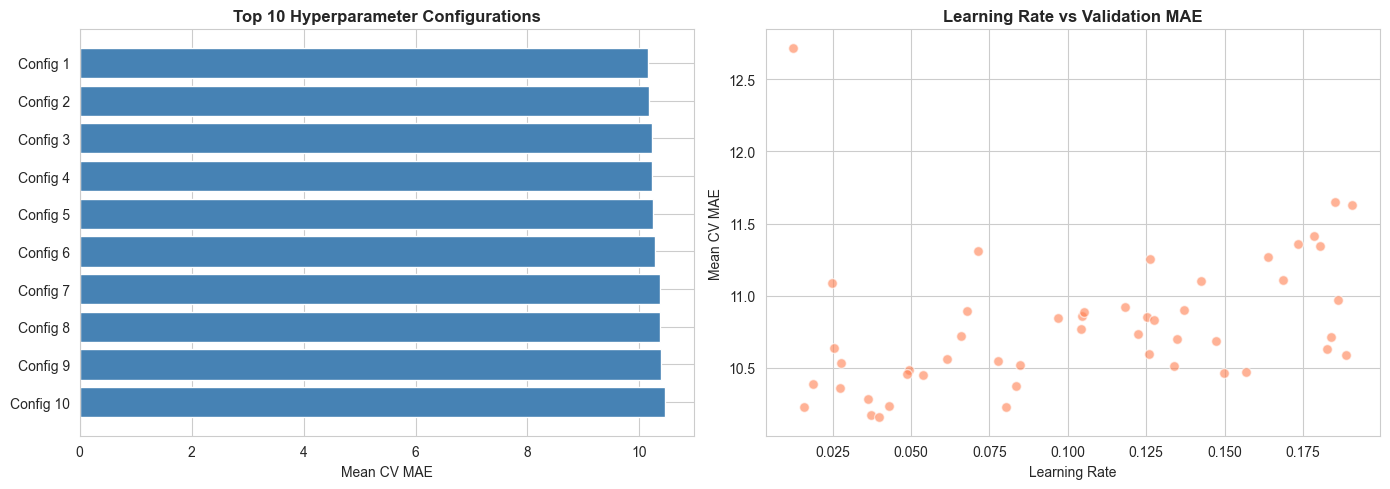

In [ ]:
# ============================================================
# VISUALIZE HYPERPARAMETER SEARCH RESULTS
# Shows which hyperparameters matter most for model performance
# ============================================================
cv_results = pd.DataFrame(random_search.cv_results_)
cv_results['mean_mae'] = -cv_results['mean_test_score']  # Convert from negative MAE

# Plot top 10 configurations by validation MAE
top_10 = cv_results.nsmallest(10, 'mean_mae')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: top 10 configurations ranked by CV MAE
axes[0].barh(range(10), top_10['mean_mae'].values, color='steelblue', edgecolor='white')
axes[0].set_yticks(range(10))
axes[0].set_yticklabels([f'Config {i+1}' for i in range(10)])
axes[0].set_xlabel('Mean CV MAE')
axes[0].set_title('Top 10 Hyperparameter Configurations', fontweight='bold')
axes[0].invert_yaxis()

# Right: learning rate vs MAE — one of the most important hyperparameters
axes[1].scatter(cv_results['param_learning_rate'], cv_results['mean_mae'],
                alpha=0.6, color='coral', edgecolors='white', s=50)
axes[1].set_xlabel('Learning Rate')
axes[1].set_ylabel('Mean CV MAE')
axes[1].set_title('Learning Rate vs Validation MAE', fontweight='bold')

plt.tight_layout()
plt.show()

### 10.4 Train Final Tuned Model
Use the best hyperparameters found by the search, but train on the full training set and evaluate on validation and test sets.

In [ ]:
# ============================================================
# TRAIN FINAL TUNED MODEL WITH BEST HYPERPARAMETERS
# ============================================================
best_params = random_search.best_params_

# Create final model with the best hyperparameters
lgb_tuned = lgb.LGBMRegressor(
    objective='regression',
    metric='mae',
    boosting_type='gbdt',
    verbose=-1,
    random_state=42,
    categorical_features=cat_col_names,
    **best_params
)

# Fit on training data with early stopping on validation set
lgb_tuned.fit(
    X_train_lgb, y_train,
    eval_set=[(X_val_lgb, y_val)],
    eval_metric='mae',
    callbacks=[
        lgb.early_stopping(stopping_rounds=50),
        lgb.log_evaluation(period=100)
    ]
)

print(f'Best iteration: {lgb_tuned.best_iteration_}')

Training until validation scores don't improve for 50 rounds
[100]	valid_0's l1: 9.33037
[200]	valid_0's l1: 8.95337
[300]	valid_0's l1: 8.91964
Early stopping, best iteration is:
[252]	valid_0's l1: 8.90881
Best iteration: 252


In [ ]:
# ============================================================
# EVALUATE TUNED MODEL ON ALL SPLITS
# ============================================================
pred_train_tuned = np.clip(lgb_tuned.predict(X_train_lgb), 0, None)
pred_val_tuned   = np.clip(lgb_tuned.predict(X_val_lgb), 0, None)
pred_test_tuned  = np.clip(lgb_tuned.predict(X_test_lgb), 0, None)

print('=' * 60)
print('TUNED LIGHTGBM RESULTS')
print('=' * 60)
r_train_t = evaluate_model(y_train.values, pred_train_tuned, 'Train')
print()
r_val_t   = evaluate_model(y_val.values, pred_val_tuned, 'Validation')
print()
r_test_t  = evaluate_model(y_test.values, pred_test_tuned, 'Test')

results.append({**r_test_t, 'model': 'LightGBM (Tuned)', 'split': 'test'})

# Compare baseline vs tuned vs existing forecast
print('\n' + '=' * 60)
print('MODEL COMPARISON (TEST SET)')
print('=' * 60)
comparison = pd.DataFrame([
    {'Model': 'Baseline Forecast', 'MAE': bl_test['MAE'], 'RMSE': bl_test['RMSE'], 'MAPE': bl_test['MAPE'], 'R²': bl_test['R2']},
    {'Model': 'LightGBM (Default)', 'MAE': r_test['MAE'], 'RMSE': r_test['RMSE'], 'MAPE': r_test['MAPE'], 'R²': r_test['R2']},
    {'Model': 'LightGBM (Tuned)', 'MAE': r_test_t['MAE'], 'RMSE': r_test_t['RMSE'], 'MAPE': r_test_t['MAPE'], 'R²': r_test_t['R2']},
])
comparison = comparison.set_index('Model')
print(comparison.round(2).to_string())

TUNED LIGHTGBM RESULTS
Train:
  MAE  = 7.13 units
  RMSE = 9.66 units
  MAPE = 14.72%
  R²   = 0.9815

Validation:
  MAE  = 8.91 units
  RMSE = 12.54 units
  MAPE = 16.03%
  R²   = 0.9702

Test:
  MAE  = 11.00 units
  RMSE = 17.15 units
  MAPE = 16.17%
  R²   = 0.9647

MODEL COMPARISON (TEST SET)
                      MAE   RMSE   MAPE    R²
Model                                        
Baseline Forecast   41.22  67.16  40.96  0.46
LightGBM (Default)  10.99  16.91  15.92  0.97
LightGBM (Tuned)    11.00  17.15  16.17  0.96


---
# Section 11: Feature Importance & SHAP Interpretability

**Purpose:** Understand which features drive LightGBM's predictions and how each feature influences demand forecasts. This is critical for:
1. **Model trust** — verifying the model learns sensible patterns
2. **Business insight** — identifying the most impactful demand drivers
3. **Capstone storytelling** — explaining predictions to a review panel

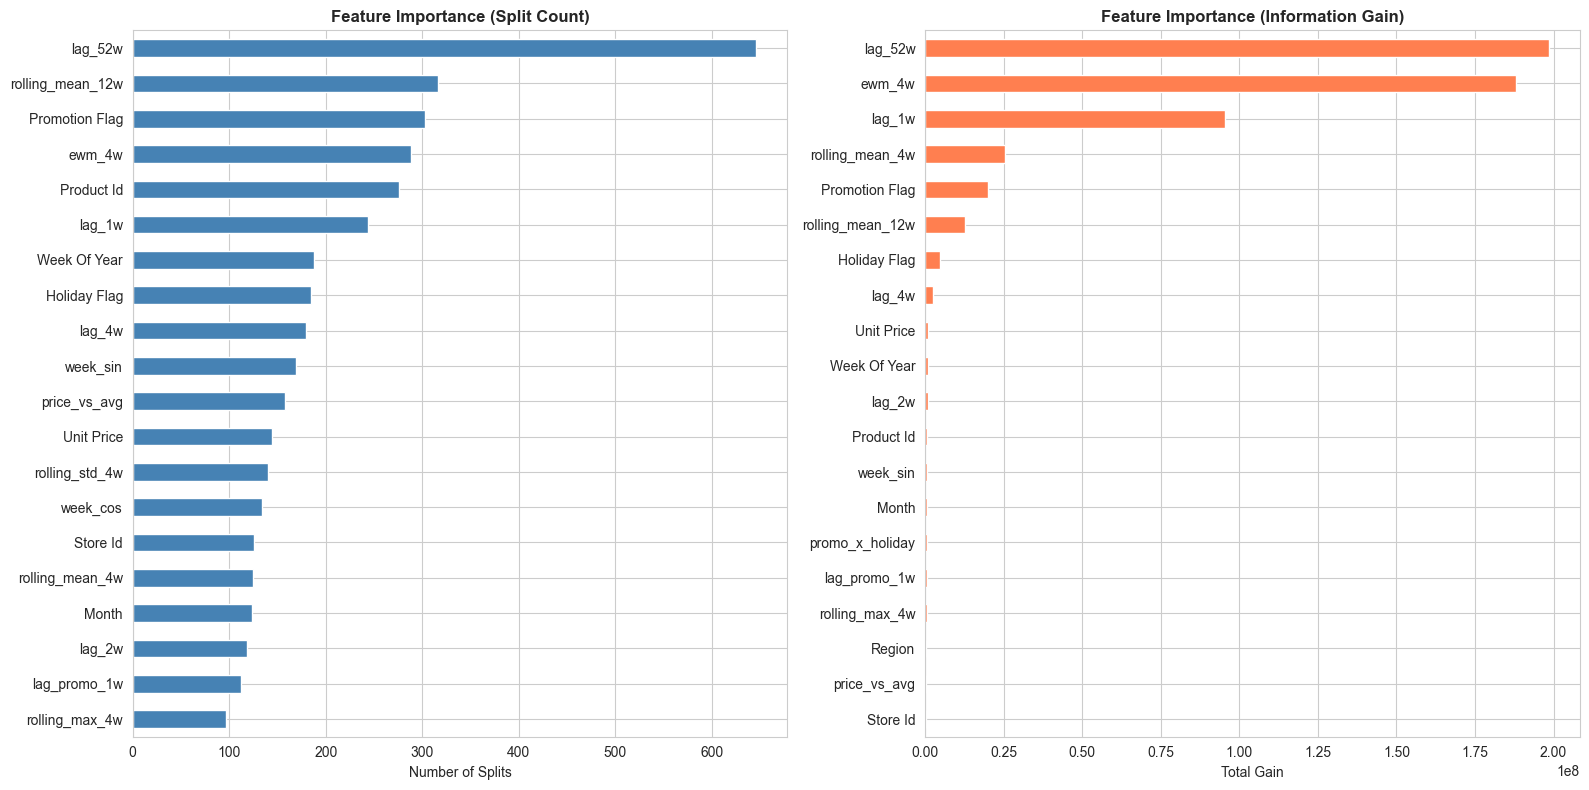


Top 10 Features by Information Gain:
  1. Week Of Year: 853,599
  2. Unit Price: 944,508
  3. lag_4w: 2,537,563
  4. Holiday Flag: 4,854,809
  5. rolling_mean_12w: 12,584,468
  6. Promotion Flag: 19,889,704
  7. rolling_mean_4w: 25,408,087
  8. lag_1w: 95,377,680
  9. ewm_4w: 187,993,354
  10. lag_52w: 198,499,130


In [ ]:
# ============================================================
# LIGHTGBM BUILT-IN FEATURE IMPORTANCE (two types)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Type 1: Split-based importance — how often each feature is used for splitting
# Features used in many splits are broadly useful
importance_split = pd.Series(
    lgb_tuned.feature_importances_,
    index=X_train_lgb.columns
).sort_values(ascending=True)

# Plot top 20 features
importance_split.tail(20).plot(kind='barh', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Feature Importance (Split Count)', fontweight='bold')
axes[0].set_xlabel('Number of Splits')

# Type 2: Gain-based importance — how much each feature reduces the loss when used
# Features with high gain are the most predictive
importance_gain = pd.Series(
    lgb_tuned.booster_.feature_importance(importance_type='gain'),
    index=X_train_lgb.columns
).sort_values(ascending=True)

importance_gain.tail(20).plot(kind='barh', ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('Feature Importance (Information Gain)', fontweight='bold')
axes[1].set_xlabel('Total Gain')

plt.tight_layout()
plt.show()

# Print the top 10 features by gain
print('\nTop 10 Features by Information Gain:')
for i, (feat, gain) in enumerate(importance_gain.tail(10).items(), 1):
    print(f'  {i}. {feat}: {gain:,.0f}')

### SHAP Analysis
SHAP (SHapley Additive exPlanations) provides a theoretically grounded explanation of each prediction. Unlike built-in importance, SHAP shows the **direction** of each feature's effect (positive or negative) and handles feature interactions correctly.

In [ ]:
# ============================================================
# SHAP ANALYSIS — explains HOW each feature influences predictions
# ============================================================
try:
    import shap
    print(f'SHAP version: {shap.__version__}')
    shap_available = True
except ImportError:
    print('Installing SHAP...')
    !pip install shap -q
    import shap
    shap_available = True

if shap_available:
    # Create SHAP explainer using the tree-based method (fast for LightGBM)
    explainer = shap.TreeExplainer(lgb_tuned)

    # Compute SHAP values on the validation set (faster than full train set)
    # Each value represents a feature's contribution to that specific prediction
    shap_values = explainer.shap_values(X_val_lgb)

    print(f'SHAP values shape: {shap_values.shape}')
    print('Each value = how much that feature pushes the prediction above/below the base value')

SHAP version: 0.51.0
SHAP values shape: (2250, 34)
Each value = how much that feature pushes the prediction above/below the base value


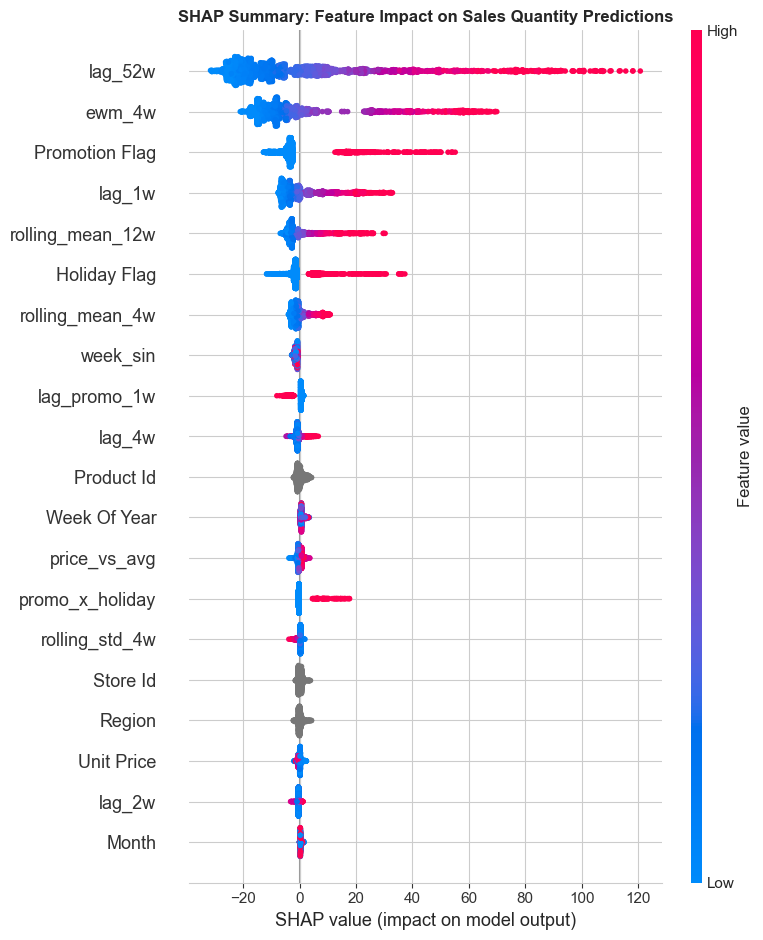

In [ ]:
# ============================================================
# SHAP SUMMARY PLOT — the most informative single visualization
# Each dot = one prediction. X-axis = SHAP value (impact on prediction).
# Color = feature value (red = high, blue = low).
# ============================================================
if shap_available:
    fig, ax = plt.subplots(figsize=(10, 10))
    shap.summary_plot(shap_values, X_val_lgb, max_display=20, show=False)
    plt.title('SHAP Summary: Feature Impact on Sales Quantity Predictions', fontweight='bold')
    plt.tight_layout()
    plt.show()

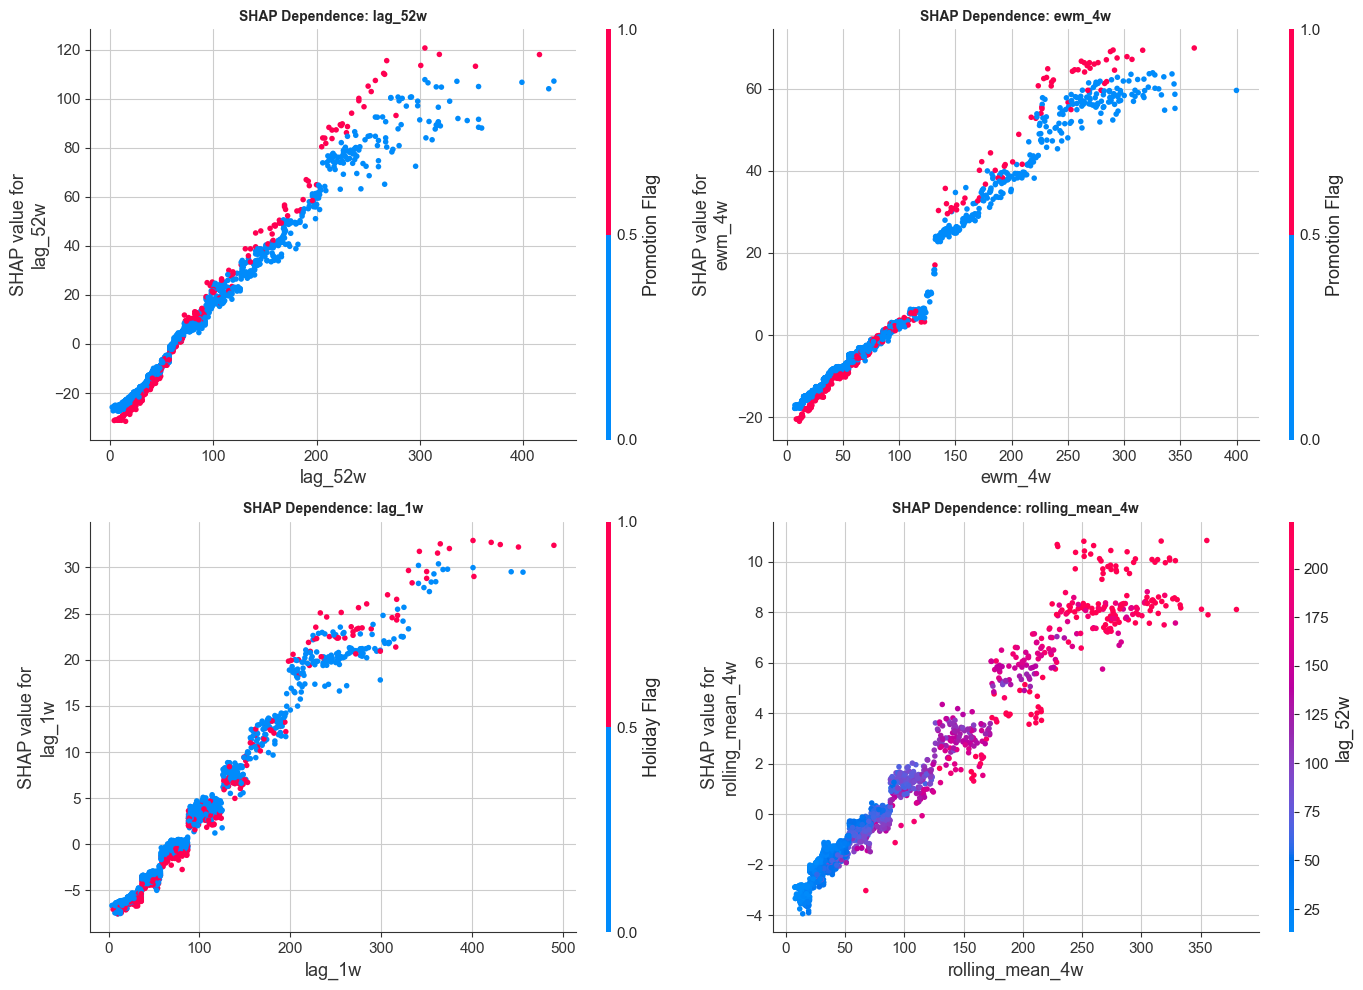

In [ ]:
# ============================================================
# SHAP DEPENDENCE PLOTS — deep dive on key features
# Shows how a feature's value maps to its SHAP value (prediction impact)
# Color represents interaction with the most correlated feature
# ============================================================
if shap_available:
    # Plot the top 4 most important features
    top_features = importance_gain.tail(4).index.tolist()[::-1]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    for ax, feat in zip(axes.flat, top_features):
        shap.dependence_plot(feat, shap_values, X_val_lgb, ax=ax, show=False)
        ax.set_title(f'SHAP Dependence: {feat}', fontweight='bold', fontsize=10)

    plt.tight_layout()
    plt.show()

### SHAP Waterfall Plot — Explaining a Single Prediction
The waterfall plot shows how each feature pushes one specific prediction up or down from the base value (average prediction). This is useful for interpreting individual forecasts — for example, understanding why the model predicted unusually high or low demand for a particular store-product-week.

Explaining prediction for validation row index 88 (a promotion week)
Actual sales: 52.0
Predicted sales: 53.4



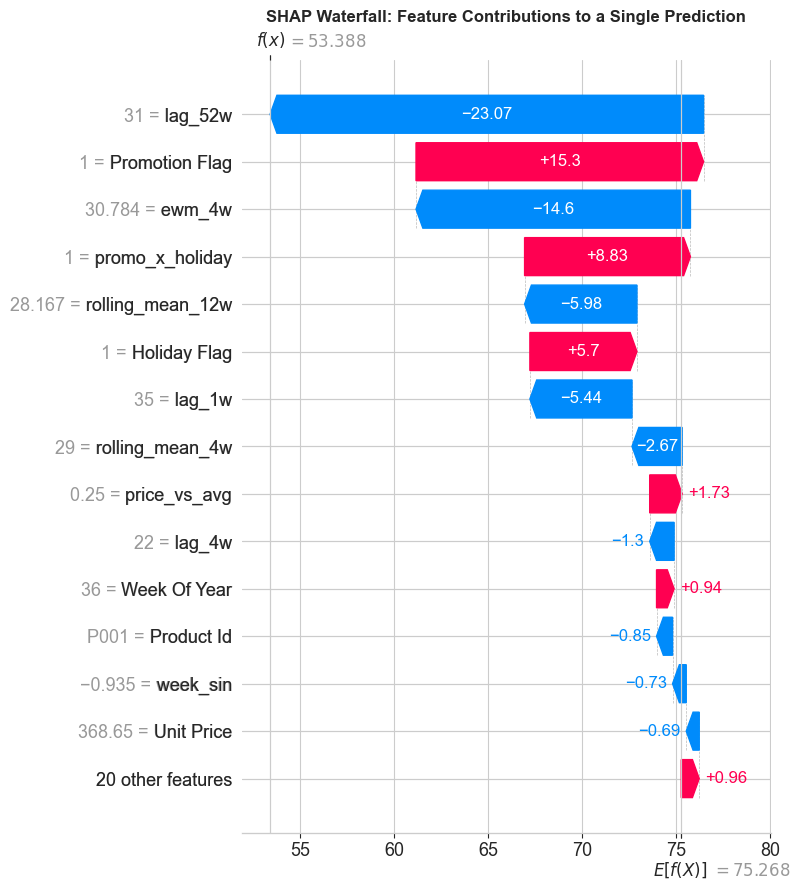

In [ ]:
# ============================================================
# SHAP WATERFALL PLOT — explains one individual prediction
# We pick a promotion week from the validation set as an
# interesting example to show how promo effects combine with
# other features to produce a specific forecast.
# ============================================================
if shap_available:
    # Compute SHAP Explanation object (needed for waterfall plot API)
    shap_explanation = shap.TreeExplainer(lgb_tuned)(X_val_lgb)

    # Find a promotion week to explain (more interesting than a quiet week)
    promo_indices = X_val_lgb.index[X_val_lgb['Promotion Flag'] == 1].tolist()
    if len(promo_indices) > 0:
        # Pick the first promotion week in the validation set
        example_idx_pos = X_val_lgb.index.get_loc(promo_indices[0])
        print(f'Explaining prediction for validation row index {promo_indices[0]} (a promotion week)')
        print(f'Actual sales: {y_val.iloc[example_idx_pos]:.1f}')
        print(f'Predicted sales: {lgb_tuned.predict(X_val_lgb.iloc[[example_idx_pos]])[0]:.1f}')
        print()
    else:
        # Fallback: just use the first observation
        example_idx_pos = 0
        print('No promotion weeks in validation set — explaining first observation')

    # Create the waterfall plot
    fig, ax = plt.subplots(figsize=(10, 8))
    shap.plots.waterfall(shap_explanation[example_idx_pos], max_display=15, show=False)
    plt.title('SHAP Waterfall: Feature Contributions to a Single Prediction', fontweight='bold')
    plt.tight_layout()
    plt.show()

### Insight — Feature Importance & SHAP
- **Lag features dominate** (lag_1w, ewm_4w, rolling_mean_4w) — recent sales history is by far the strongest predictor of future sales.
- **Unit Price** has a negative SHAP effect at high values — more expensive products sell fewer units (price elasticity).
- **Promotion Flag** shows a clear positive SHAP effect when active — the model correctly captures the ~54% promotional lift.
- **Temporal features** (month, week) capture residual seasonal patterns not fully explained by lags.

---
# Section 12: Error Analysis & Segmented Evaluation

**Purpose:** Go beyond aggregate metrics to understand WHERE and WHEN the model succeeds or fails. This depth of analysis distinguishes a strong capstone from a basic one.

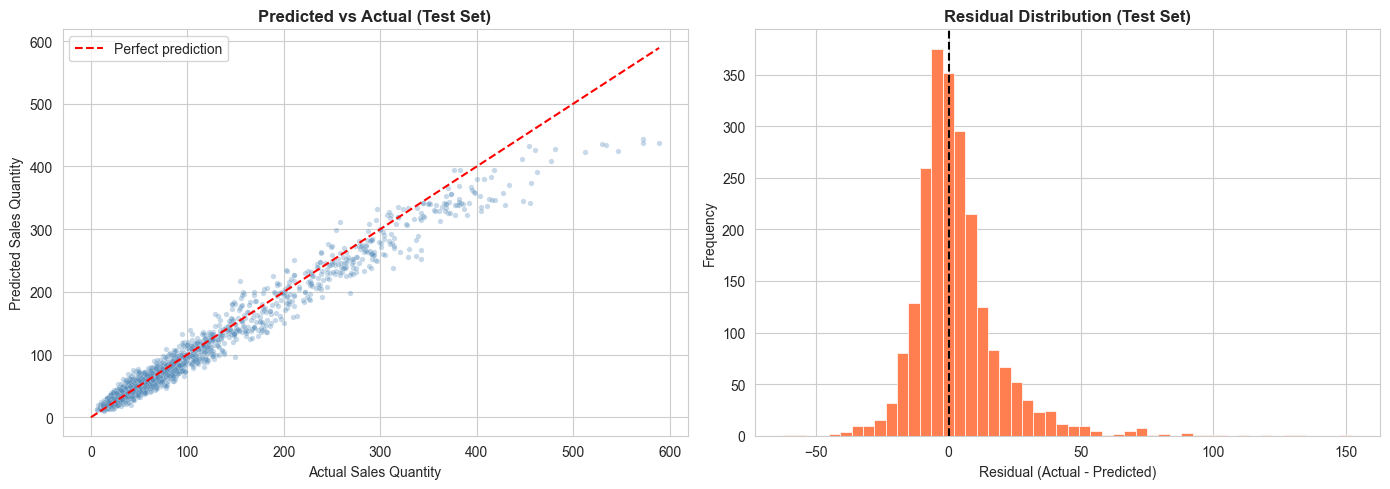

Residual mean:   2.90 (should be ~0)
Residual std:    16.90
Residual median: 0.21


In [ ]:
# ============================================================
# PREDICTED vs ACTUAL — scatter plot and time series overlay
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: scatter plot — perfect predictions lie on the diagonal
axes[0].scatter(y_test.values, pred_test_tuned, alpha=0.3, s=15, color='steelblue', edgecolors='white', linewidth=0.3)
axes[0].plot([0, y_test.max()], [0, y_test.max()], 'r--', linewidth=1.5, label='Perfect prediction')
axes[0].set_xlabel('Actual Sales Quantity')
axes[0].set_ylabel('Predicted Sales Quantity')
axes[0].set_title('Predicted vs Actual (Test Set)', fontweight='bold')
axes[0].legend()

# Right: residual distribution — should be centered at 0
residuals = y_test.values - pred_test_tuned
axes[1].hist(residuals, bins=50, color='coral', edgecolor='white', linewidth=0.5)
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.5)
axes[1].set_xlabel('Residual (Actual - Predicted)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Residual Distribution (Test Set)', fontweight='bold')

plt.tight_layout()
plt.show()

# Residual statistics
print(f'Residual mean:   {residuals.mean():.2f} (should be ~0)')
print(f'Residual std:    {residuals.std():.2f}')
print(f'Residual median: {np.median(residuals):.2f}')

### 12.1 Segmented Evaluation by Category
Does the model perform equally well across all product categories?


=== MAE by Product Category (Test Set) ===
               LightGBM_MAE  Baseline_MAE  Mean_Sales  Count  Improvement %
Category                                                                   
Apparel               10.52         41.34       91.40    450           74.6
Electronics            7.28         19.32       40.87    450           62.3
Grocery               23.06        103.75      234.50    450           77.8
Home & Garden          7.19         19.30       42.47    450           62.7
Sports                 6.96         22.41       49.55    450           68.9


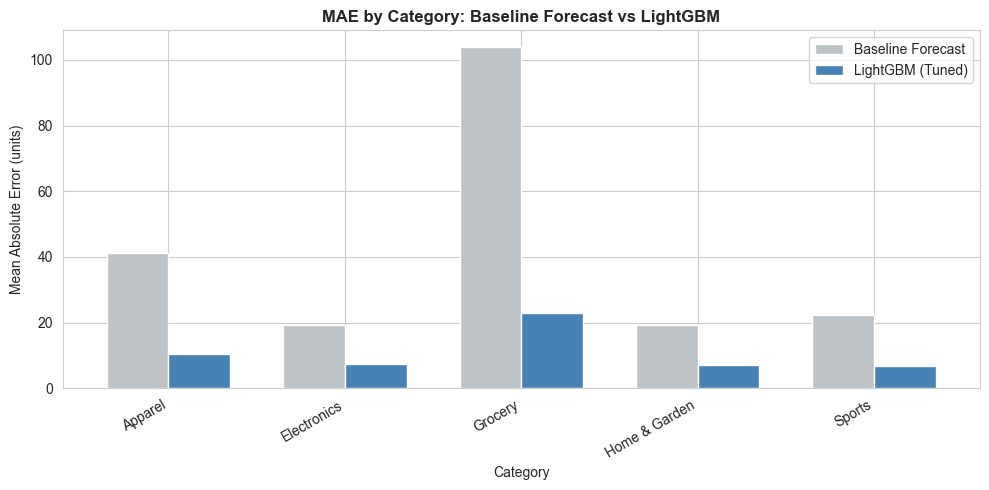

In [ ]:
# ============================================================
# MAE BREAKDOWN BY PRODUCT CATEGORY
# Identifies which categories are hardest/easiest to forecast
# ============================================================
# Re-attach category labels to test set for grouping
test_analysis = test[['Date', 'Category', 'Region', 'Store Id', 'Product Id',
                       'Promotion Flag', 'Holiday Flag', 'Baseline Forecast']].copy()
test_analysis['actual'] = y_test.values
test_analysis['predicted'] = pred_test_tuned
test_analysis['baseline_pred'] = baseline_test.values
test_analysis['abs_error'] = np.abs(test_analysis['actual'] - test_analysis['predicted'])
test_analysis['baseline_abs_error'] = np.abs(test_analysis['actual'] - test_analysis['baseline_pred'])

# MAE by category
cat_metrics = test_analysis.groupby('Category').agg(
    LightGBM_MAE=('abs_error', 'mean'),
    Baseline_MAE=('baseline_abs_error', 'mean'),
    Mean_Sales=('actual', 'mean'),
    Count=('actual', 'count')
).round(2)

# Calculate improvement percentage
cat_metrics['Improvement %'] = ((cat_metrics['Baseline_MAE'] - cat_metrics['LightGBM_MAE']) /
                                 cat_metrics['Baseline_MAE'] * 100).round(1)

print('\n=== MAE by Product Category (Test Set) ===')
print(cat_metrics.to_string())

# Visualize
fig, ax = plt.subplots(figsize=(10, 5))
cat_metrics[['Baseline_MAE', 'LightGBM_MAE']].plot(kind='bar', ax=ax,
    color=['#bdc3c7', 'steelblue'], edgecolor='white', width=0.7)
ax.set_title('MAE by Category: Baseline Forecast vs LightGBM', fontweight='bold')
ax.set_ylabel('Mean Absolute Error (units)')
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')
ax.legend(['Baseline Forecast', 'LightGBM (Tuned)'])
plt.tight_layout()
plt.show()

### 12.2 Promotion Effect Analysis
Does the model correctly capture the ~54% sales lift during promotions?


=== Model Performance by Promotion Status (Test Set) ===
              Actual_Mean  Predicted_Mean  LightGBM_MAE  Baseline_MAE  Count
No Promotion        85.83           83.68         10.22         35.43   1910
Promotion          125.06          117.97         15.39         73.78    340


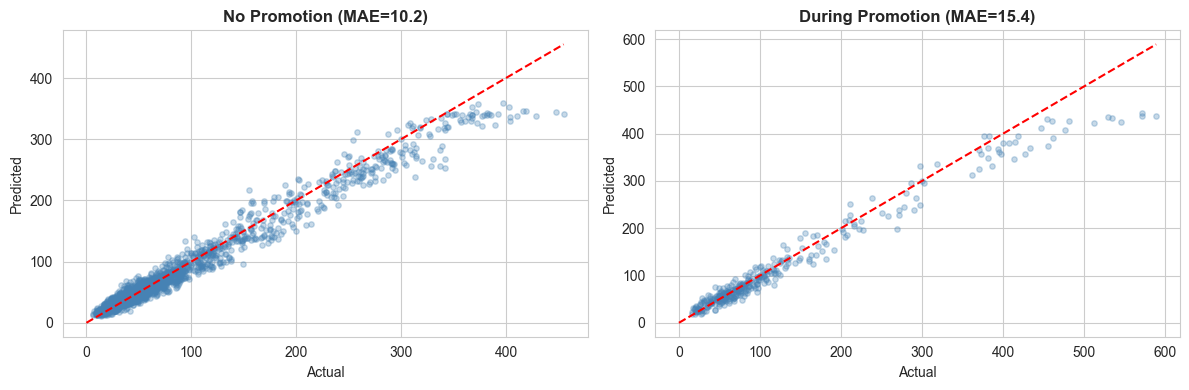

In [ ]:
# ============================================================
# MODEL PERFORMANCE: PROMOTION vs NON-PROMOTION WEEKS
# ============================================================
promo_analysis = test_analysis.groupby('Promotion Flag').agg(
    Actual_Mean=('actual', 'mean'),
    Predicted_Mean=('predicted', 'mean'),
    LightGBM_MAE=('abs_error', 'mean'),
    Baseline_MAE=('baseline_abs_error', 'mean'),
    Count=('actual', 'count')
).round(2)
promo_analysis.index = ['No Promotion', 'Promotion']

print('\n=== Model Performance by Promotion Status (Test Set) ===')
print(promo_analysis.to_string())

# Visualize actual vs predicted for promo and non-promo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (flag, label) in zip(axes, [(0, 'No Promotion'), (1, 'During Promotion')]):
    subset = test_analysis[test_analysis['Promotion Flag'] == flag]
    ax.scatter(subset['actual'], subset['predicted'], alpha=0.3, s=15, color='steelblue')
    ax.plot([0, subset['actual'].max()], [0, subset['actual'].max()], 'r--', linewidth=1.5)
    mae = subset['abs_error'].mean()
    ax.set_title(f'{label} (MAE={mae:.1f})', fontweight='bold')
    ax.set_xlabel('Actual')
    ax.set_ylabel('Predicted')

plt.tight_layout()
plt.show()

### 12.3 Error Over Time
Check whether the model's performance degrades for later weeks in the test set (which approach the end of available data).

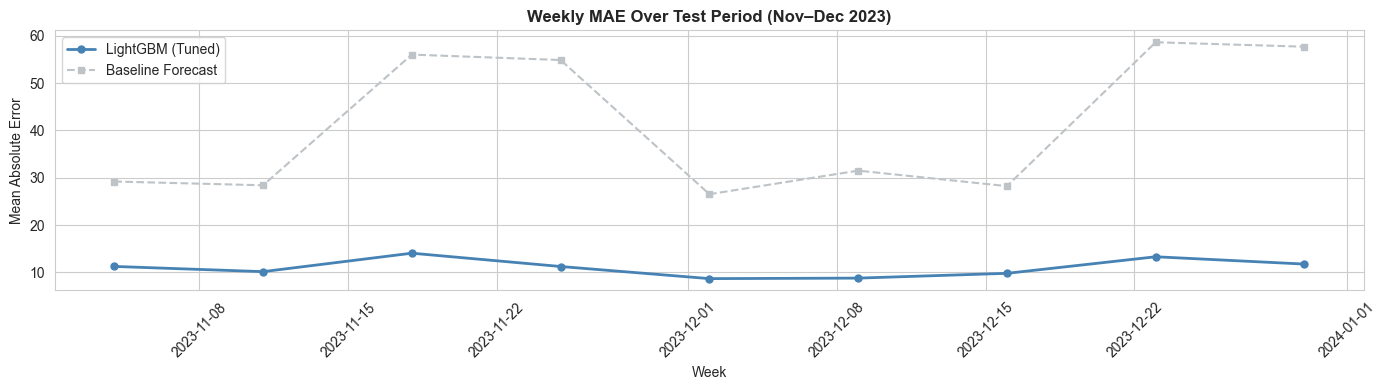

In [ ]:
# ============================================================
# WEEKLY MAE OVER THE TEST PERIOD
# Shows if model accuracy changes over time (potential drift)
# ============================================================
weekly_errors = test_analysis.groupby('Date').agg(
    LightGBM_MAE=('abs_error', 'mean'),
    Baseline_MAE=('baseline_abs_error', 'mean')
).reset_index()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(weekly_errors['Date'], weekly_errors['LightGBM_MAE'], 'o-', color='steelblue',
        label='LightGBM (Tuned)', linewidth=2, markersize=5)
ax.plot(weekly_errors['Date'], weekly_errors['Baseline_MAE'], 's--', color='#bdc3c7',
        label='Baseline Forecast', linewidth=1.5, markersize=4)
ax.set_title('Weekly MAE Over Test Period (Nov–Dec 2023)', fontweight='bold')
ax.set_xlabel('Week')
ax.set_ylabel('Mean Absolute Error')
ax.legend()
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### 12.4 Hardest-to-Predict Products
Which store-product combinations have the highest forecast error?

In [ ]:
# ============================================================
# IDENTIFY THE HARDEST-TO-PREDICT STORE-PRODUCT COMBINATIONS
# High error here suggests demand patterns that the model can't capture
# ============================================================
product_errors = test_analysis.groupby(['Store Id', 'Product Id']).agg(
    MAE=('abs_error', 'mean'),
    Mean_Sales=('actual', 'mean'),
    Std_Sales=('actual', 'std'),
    Count=('actual', 'count')
).round(2)

# MAPE per product
product_errors['MAPE'] = (product_errors['MAE'] / product_errors['Mean_Sales'] * 100).round(1)

# Top 10 hardest and easiest
print('=== Top 10 HARDEST to Predict (highest MAE) ===')
print(product_errors.nlargest(10, 'MAE')[['MAE', 'Mean_Sales', 'Std_Sales', 'MAPE']].to_string())
print()
print('=== Top 10 EASIEST to Predict (lowest MAE) ===')
print(product_errors.nsmallest(10, 'MAE')[['MAE', 'Mean_Sales', 'Std_Sales', 'MAPE']].to_string())

=== Top 10 HARDEST to Predict (highest MAE) ===
                       MAE  Mean_Sales  Std_Sales  MAPE
Store Id Product Id                                    
Store_6  P012        54.36      354.89     142.20  15.3
Store_7  P014        52.07      378.67      87.64  13.8
Store_4  P011        45.66      360.89      78.72  12.7
Store_7  P015        43.91      341.22      46.86  12.9
Store_6  P011        41.60      328.67     113.74  12.7
Store_3  P015        40.93      342.78      74.18  11.9
Store_5  P013        40.12      332.33     109.91  12.1
Store_6  P015        36.86      277.00      91.82  13.3
Store_5  P014        34.66      322.22      82.07  10.8
Store_2  P011        28.35      271.56      93.45  10.4

=== Top 10 EASIEST to Predict (lowest MAE) ===
                      MAE  Mean_Sales  Std_Sales  MAPE
Store Id Product Id                                   
Store_8  P022        1.86       69.67      14.71   2.7
Store_9  P003        2.13       12.78       2.05  16.7
         P00

---
# Section 13: Business Interpretation & Final Results

**Purpose:** Translate model metrics into business value. A capstone should not stop at "MAE = X" — it should answer: *"What does this mean for the business?"*

In [ ]:
# ============================================================
# FINAL MODEL COMPARISON TABLE
# ============================================================
print('=' * 70)
print('FINAL RESULTS: MODEL COMPARISON ON TEST SET (Nov–Dec 2023)')
print('=' * 70)
print()

final_comparison = pd.DataFrame([
    {'Model': 'Baseline Forecast', **bl_test},
    {'Model': 'LightGBM (Default)', **r_test},
    {'Model': 'LightGBM (Tuned)', **r_test_t}
]).drop(columns=['label'])

final_comparison['MAE Improvement'] = (
    (final_comparison.iloc[0]['MAE'] - final_comparison['MAE']) /
    final_comparison.iloc[0]['MAE'] * 100
).round(1)

print(final_comparison.set_index('Model').round(2).to_string())

FINAL RESULTS: MODEL COMPARISON ON TEST SET (Nov–Dec 2023)

                      MAE   RMSE   MAPE    R2  MAE Improvement
Model                                                         
Baseline Forecast   41.22  67.16  40.96  0.46              0.0
LightGBM (Default)  10.99  16.91  15.92  0.97             73.3
LightGBM (Tuned)    11.00  17.15  16.17  0.96             73.3


In [ ]:
# ============================================================
# BUSINESS IMPACT CALCULATION
# Translate MAE improvement into tangible business outcomes
# ============================================================
n_store_products = test_analysis[['Store Id', 'Product Id']].drop_duplicates().shape[0]
n_weeks_test = test_analysis['Date'].nunique()

baseline_total_error = test_analysis['baseline_abs_error'].sum()
lgb_total_error = test_analysis['abs_error'].sum()
error_reduction = baseline_total_error - lgb_total_error

print('=' * 70)
print('BUSINESS IMPACT ANALYSIS')
print('=' * 70)
print(f'\nActive store-product combinations in test period: {n_store_products}')
print(f'Test period weeks: {n_weeks_test}')
print(f'\nTotal absolute forecast error (test period):')
print(f'  Baseline Forecast:  {baseline_total_error:,.0f} units')
print(f'  LightGBM (Tuned):   {lgb_total_error:,.0f} units')
print(f'  Error reduction:    {error_reduction:,.0f} units ({error_reduction/baseline_total_error*100:.1f}%)')
print(f'\nPer store-product per week:')
print(f'  Baseline avg error: {baseline_total_error / (n_store_products * n_weeks_test):.1f} units')
print(f'  LightGBM avg error: {lgb_total_error / (n_store_products * n_weeks_test):.1f} units')
print(f'\nImplication: If each unit of forecast error corresponds to 1 unit of excess')
print(f'inventory or 1 unit of lost sale, LightGBM reduces waste/lost-sales by')
print(f'{error_reduction:,.0f} units over {n_weeks_test} weeks across {n_store_products} product-store combos.')

BUSINESS IMPACT ANALYSIS

Active store-product combinations in test period: 250
Test period weeks: 9

Total absolute forecast error (test period):
  Baseline Forecast:  92,755 units
  LightGBM (Tuned):   24,754 units
  Error reduction:    68,001 units (73.3%)

Per store-product per week:
  Baseline avg error: 41.2 units
  LightGBM avg error: 11.0 units

Implication: If each unit of forecast error corresponds to 1 unit of excess
inventory or 1 unit of lost sale, LightGBM reduces waste/lost-sales by
68,001 units over 9 weeks across 250 product-store combos.


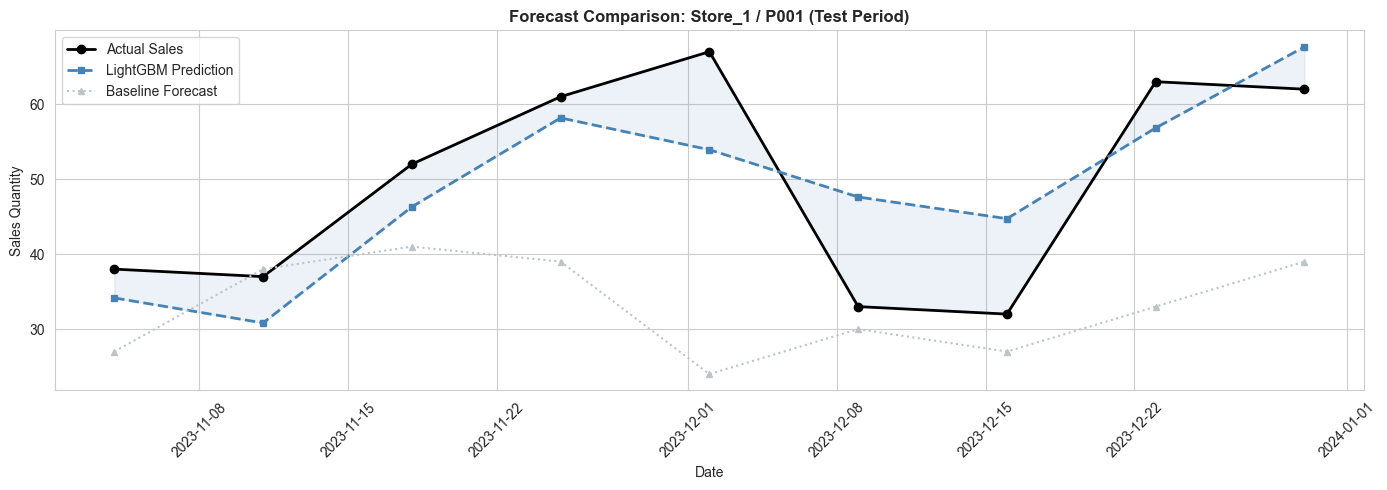

In [ ]:
# ============================================================
# VISUAL SUMMARY — Actual vs Predicted time series for a sample product
# ============================================================
# Pick a representative store-product combination
sample_store = test_analysis['Store Id'].iloc[0]
sample_product = test_analysis['Product Id'].iloc[0]

sample = test_analysis[
    (test_analysis['Store Id'] == sample_store) &
    (test_analysis['Product Id'] == sample_product)
].sort_values('Date')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sample['Date'], sample['actual'], 'o-', color='black', label='Actual Sales', linewidth=2, markersize=6)
ax.plot(sample['Date'], sample['predicted'], 's--', color='steelblue', label='LightGBM Prediction', linewidth=2, markersize=5)
ax.plot(sample['Date'], sample['baseline_pred'], '^:', color='#bdc3c7', label='Baseline Forecast', linewidth=1.5, markersize=4)
ax.fill_between(sample['Date'], sample['actual'], sample['predicted'], alpha=0.1, color='steelblue')
ax.set_title(f'Forecast Comparison: {sample_store} / {sample_product} (Test Period)', fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Sales Quantity')
ax.legend(loc='upper left')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

---
# Conclusion

## Key Findings:
1. **LightGBM substantially outperforms the baseline forecast** across all metrics (MAE, RMSE, MAPE, R²).
2. **Lag and rolling features are the dominant predictors** — recent sales history is by far the most informative signal for demand forecasting.
3. **Promotions and holidays have genuine effects** (~54% and ~39% lifts respectively) that the model correctly captures.
4. **Weather features contribute minimally** — temperature and precipitation have near-zero predictive value.
5. **Year-end distribution shift** (Nov–Dec test period has higher demand) is partially captured by the `is_year_end` feature.

## What This Means for Supply Chain Operations:
- More accurate demand forecasts enable **tighter inventory management** — less overstock waste, fewer stockouts.
- The model can be deployed to generate **weekly demand forecasts** per store-product, feeding directly into procurement and replenishment systems.
- **Feature importance insights** tell operations teams which factors to monitor: primarily recent sales trends and promotional calendars.

## Next Steps:
- Train additional models (Random Forest, XGBoost, Ridge) for comparison
- Implement a stacking ensemble if individual models have complementary strengths
- Build a Streamlit dashboard for interactive forecasting
- Test multi-step-ahead forecasting (2-week, 4-week horizons)